# Experiment: probability calibration of off-the-shelf Jev

**Exploratory pilot, reanalyzed from cached predictions.** The original tables and figures retain the historical filtered population and correction. Revised diagnostics and uncertainty appear alongside them below; none is independent confirmation.

## Abstract

We evaluated Jev 1.13.0 on a binary-probability experiment (coins and thresholds from eight distribution families), two-dice sums, and three UCI datasets: 85 known-probability cases and 600 held-out records, with 120 separate calibration records per UCI dataset. One protocol compares Brier loss and calibration across eight task–input conditions; synthetic loss is exact in expectation and real-data loss uses observed outcomes. Noul had lower Brier loss in 7 of eight conditions and numerically lower Expected Calibration Error (ECE; the average gap between grouped predictions and reference rates) in 8 of eight. For a fair coin, Choice predicted 93% heads and Noul 46%. Raw real-data ECE ranged from 9.3 to 40.0 percentage points. Recalibration reduced the Brier point estimate in 5 of six real-data comparisons but worsened Bank Marketing Noul from 0.1935 to 0.2716. **Jev was not consistently well calibrated: stronger synthetic probability recovery did not establish reliable probabilities on real data.**

## 1. Objective and protocol

We evaluated raw and recalibrated Jev probabilities on synthetic scenarios and three UCI datasets. Summary comparisons appear in the main report; individual experiment results appear in the appendix.

## 2. Experimental design

### Tasks and observed outcomes

**Choice** returns probabilities for two mutually exclusive answers. **Noul** returns a probability-like score for one statement. We ask both about the same event and also ask Noul about its opposite. The main report evaluates known-probability recovery against exact probabilities and real-event forecasts against observed outcomes. The separate answer-confidence diagnostic compares confidence in the chosen answer with correctness; event probabilities are never scored against answer correctness.

| Experiment | Input | Target event | Requests |
|---|---|---|---:|
| Binary probability tests | 15 stated coin probabilities + 48 threshold questions from eight distributions | Heads, or a draw at/below a threshold | 63 |
| Two dice | Two independent fair six-sided dice, with or without the exact sum probability | The next roll has a specified sum from 2 to 12 | 22 |
| South German Credit | 20 decoded credit-record features | Contract not complied with (`kredit=0`) | 320 |
| Bank Marketing | 19 features; completed-call duration excluded | Deposit subscription (`y=yes`) | 320 |
| Online Shoppers | 16 features; transaction-related PageValues excluded | Session ends in purchase (`Revenue=True`) | 320 |

**Binary probability tests combine 15 coin-toss cases and 48 distribution-threshold cases.** Both produce an event indicator: 1 if the event happens, otherwise 0. If its chance is `q`, this is a Bernoulli trial—the same outcome model as a coin with heads probability `q`. For example, a uniform draw from 0 to 1 being at most 0.1 has the same binary outcome distribution as a coin with a 10% heads probability. The Monte Carlo simulation therefore uses the same binary sampling and Brier formula for both.

We retain three conditions within this experiment: coins with stated probabilities, thresholds with stated probabilities, and thresholds with only the distribution described. The last condition also tests whether Jev can derive the event probability. A pooled result would mix that task with probability copying and give 48 threshold cases more weight than 15 coin cases. Different event probabilities also change unavoidable Brier loss, so subgroup comparisons retain that context. Pooling calibration bins can cancel opposite errors. The summary keeps these conditions adjacent and separate. Dice remain a separate experiment because the 11 sums share each simulated roll and must jointly account for all outcomes.

Each request contains three questions, giving **1,045 requests and 3,135 question scores**. For each real dataset, 120 records fit probability corrections and a separate 200 evaluate them. Synthetic probabilities are known exactly; real-data probabilities are unknown, so actual binary labels supply the evaluation outcomes. The 85 synthetic prompt cases represent 50 event definitions and 24 conservative generating groups; the 960 real records have unverified customer independence. Each request appears once in this cache; Monte Carlo repetitions add no model evaluations.

**Question format** identifies what Jev is told: `explicit` supplies the exact event probability; `parameters` supplies the generating process only. The stored column `track` uses these labels. Coins use only the explicit format. Dice use both formats for each of 11 sums. The other distributions use both formats for each of 24 threshold events.

| Data field | Meaning |
|---|---|
| `q` | Known probability of the synthetic event; not available for real records |
| `choice_p` | Choice probability assigned to the event |
| `noul_p` | Noul score assigned to that same event |
| `complement_p` | Separate Noul score for the opposite event; not computed as `1 − noul_p` |
| `y` | Observed real-data outcome: 1 when the target event occurred, otherwise 0 |

**Brier score** is the mean squared gap between a probability and its binary outcome. For a known event probability `q` and forecast `p`, expected Brier loss is `q(1−q) + (p−q)²`. The **oracle** predicts `q` and incurs only the first term: unavoidable randomness. Probability MAE is mean absolute error, `mean(|p−q|)`. ECE10 is Expected Calibration Error: the weighted mean absolute gap between forecast and event-rate averages in ten probability groups. Lower values are better for these errors. The normalized calibration penalty uses squared group gaps divided by the overall event rate times its complement; it is not ECE.

We evaluated 1,045 inputs: 15 coin-toss cases, 22 two-dice cases, 48 distribution-threshold cases, and 320 records per UCI dataset. Model: Jev 1.13.0. Seed: 78. Each request contained Choice, Noul, and the opposite-event Noul question. No few-shot examples were supplied.

For UCI data, predictors were decoded before prompt serialization. Targets and row identifiers were excluded from model inputs. In the historical pilot, repeated feature rows were reduced to their first occurrence; all rows in conflicting-label groups were removed. This changes the evaluation population; the historical results remain a sensitivity analysis. The revised source loader preserves separate observations, including identical features with conflicting outcomes; only proven duplicate exports may be collapsed. Bank duration and shopper PageValues were excluded. Bank records used chronological 60/20/20 blocks; the other datasets used stratified 60/20/20 partitions. We selected 120 calibration and 200 test records without further class balancing. The corrected credit data retain the source's oversampled adverse-outcome prevalence.

Baselines use the same features and test records. Logistic regression uses standardized numeric features, one-hot categorical features, C=1, and at most 3,000 iterations. CatBoost uses 300 trees, depth 6, learning rate 0.05, and CPU execution. No hyperparameters were selected from test outcomes. Historical corrections fit logistic regression to clipped Jev logits (epsilon=1e-6, C=1e6), separately by dataset and interface. Clipping is confined to correction inputs; raw log loss retains infinite values.

Synthetic evaluation uses 500 sets of 2,000 outcomes. Dice sums share a multinomial count vector within each set. UCI metrics use actual labels, not generated labels. Brier intervals and paired correction-change intervals use 1,000 paired bootstrap resamples of the 200 test records. They are conditional on this split and fitted models; record independence is assumed. Bank temporal dependence and unavailable customer IDs limit interval interpretation. Revised comparisons add raw, intercept-only, and regularized intercept-plus-slope arms with fixed settings selected without test tuning. They distinguish fixed-calibrator intervals from independently resampled calibration/refit and test intervals; grouping and temporal assumptions are stated below.

### 2.1 Data and experiment settings

The cells below inspect saved source data, regenerate the scenarios, and read cached baseline predictions and Jev responses. The historical execution sent 1,045 requests; this revision makes no API calls and writes derived outputs to a new directory. Seed 78 identifies the original sampled records and simulated outcomes.

In [1]:
# ruff: noqa: E501
import hashlib
import json
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from scipy import stats
from scipy.special import xlogy

from jev_research.evaluation import evaluate_predictions
from jev_research.population import load_population
from jev_research.revised_analysis import load_cached_run

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/uv.sh").exists())
SEED = 78
SOURCE = ROOT / "runs/04-jev-calibration-20260920T074937231226Z"
REVISION = ROOT / "runs/revised-exploratory-v1"
PILOT_NOTEBOOK = REVISION / "04_jev_calibration_report.pilot.ipynb"
RUN = (
    ROOT / "runs" / ("04-jev-calibration-revised-" + datetime.now(UTC).strftime("%Y%m%dT%H%M%S%fZ"))
)
RUN.mkdir(parents=True, exist_ok=False)
print("Cached pilot:", SOURCE.relative_to(ROOT))
print("Derived experiment files:", RUN.relative_to(ROOT), "— no API calls")

Cached pilot: runs/04-jev-calibration-20260920T074937231226Z
Derived experiment files: runs/04-jev-calibration-revised-20260922T050337437781Z — no API calls


In [2]:
# ruff: noqa: E501
SOURCES = {
    "south-german-credit": {
        "url": "https://archive.ics.uci.edu/static/public/522/south+german+credit.zip",
        "sha256": "0b40d40eb7321693d559e247a556f88a6cc8df8489c3cb2ae084db7592584551",
    },
    "bank-marketing": {
        "url": "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
        "sha256": "e0bf5f5de5b846e2f18e9d90606637267d46dfa260e0f17bb12e605db5efbeb4",
    },
    "online-shoppers": {
        "url": "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip",
        "sha256": "2972e6184d3ad7beaaa831d9fc2b059dc3ee29df69d1ec593c466a5cd8485d14",
    },
}
DATA = ROOT / "data/uci"
for slug, source in SOURCES.items():
    archive = DATA / f"{slug}.zip"
    if not archive.exists():
        raise FileNotFoundError(f"Cached source archive required: {archive}")
    assert hashlib.sha256(archive.read_bytes()).hexdigest() == source["sha256"]

### 2.2 Scenario generation

Coins cover 15 heads probabilities. Dice enumerate all 36 ordered outcomes. The remaining cases ask threshold questions about eight distributions. The tables show the exact probabilities for the original scenarios.

In [3]:
# ruff: noqa: E501
def scenarios() -> list[dict]:
    cases = []

    def add(family, track, state, event, opposite, q, true_key="event", false_key="not_event"):
        cases.append(
            dict(
                scenario_id=f"{family}-{track}-{len(cases):03d}",
                family=family,
                track=track,
                state=state,
                event=event,
                opposite=opposite,
                q=float(q),
                true_key=true_key,
                false_key=false_key,
            )
        )

    for p in [0, 0.01, 0.05, 0.1, 0.2, 0.4, 0.49, 0.5, 0.51, 0.6, 0.8, 0.9, 0.95, 0.99, 1]:
        add(
            "bernoulli",
            "explicit",
            f"A coin comes up heads {100 * p:g}% of the time and tails {100 * (1 - p):g}% "
            "of the time. Flips are independent. The next flip has not happened.",
            "The next coin flip comes up heads.",
            "The next coin flip comes up tails.",
            p,
            "heads",
            "tails",
        )
    families = [
        ("uniform", stats.uniform(0, 1), [0.1, 0.5, 0.9], "Uniform(0, 1)"),
        ("normal", stats.norm(0, 1), [-1, 0, 1], "Normal with mean 0 and standard deviation 1"),
        ("exponential", stats.expon(scale=1), [0.1, 0.7, 3], "Exponential with rate 1"),
        ("poisson", stats.poisson(2), [0, 2, 5], "Poisson with mean 2"),
        (
            "binomial",
            stats.binom(10, 0.3),
            [0, 3, 7],
            "Binomial with 10 trials and success probability 0.3",
        ),
        (
            "student_t",
            stats.t(3),
            [-2, 0, 2],
            "Student-t with 3 degrees of freedom, location 0 and scale 1",
        ),
        (
            "lognormal",
            stats.lognorm(s=1, scale=1),
            [0.2, 1, 5],
            "Lognormal with log-location 0 and log-scale 1",
        ),
    ]
    for family, distribution, thresholds, description in families:
        for threshold in thresholds:
            q = distribution.cdf(threshold)
            state = f"X is a fresh random draw from {description}. The draw has not happened."
            event = f"The next draw X is less than or equal to {threshold:g}."
            opposite = f"The next draw X is greater than {threshold:g}."
            add(family, "parameters", state, event, opposite, q)
            add(
                family,
                "explicit",
                state + f" The probability that X <= {threshold:g} is {q:.12g}.",
                event,
                opposite,
                q,
            )
    for threshold in [-2, 0, 2]:
        q = 0.5 * stats.norm(-2, 1).cdf(threshold) + 0.5 * stats.norm(2, 1).cdf(threshold)
        state = (
            "Choose one of two normal components with equal probability, then draw X. "
            "Their means are -2 and 2; both standard deviations are 1. The draw has not happened."
        )
        event = f"The next draw X is less than or equal to {threshold}."
        opposite = f"The next draw X is greater than {threshold}."
        add("normal_mixture", "parameters", state, event, opposite, q)
        add(
            "normal_mixture",
            "explicit",
            state + f" P(X <= {threshold}) = {q:.12g}.",
            event,
            opposite,
            q,
        )
    return cases

In [4]:
# ruff: noqa: E501
def dice_scenarios():
    sums = np.arange(2, 13)
    counts = np.array([sum(a + b == s for a in range(1, 7) for b in range(1, 7)) for s in sums])
    q = counts / 36
    assert counts.sum() == 36 and counts[5] == 6
    cases = []
    for total, count, probability in zip(sums, counts, q, strict=True):
        state = (
            "Two independent fair six-sided dice, each numbered 1 through 6, "
            "will be rolled once. The roll has not happened."
        )
        for track in ["parameters", "explicit"]:
            cases.append(
                {
                    "scenario_id": f"two-dice-{track}-sum-{total}",
                    "family": "two_dice",
                    "track": track,
                    "sum": int(total),
                    "q": float(probability),
                    "state": state
                    + (
                        f" The probability that their sum equals {total} "
                        f"is {count}/36 ({probability:.12g})."
                        if track == "explicit"
                        else ""
                    ),
                    "event": f"The next roll's sum equals {total}.",
                    "opposite": f"The next roll's sum does not equal {total}.",
                    "true_key": "equals_sum",
                    "false_key": "other_sum",
                }
            )
    return cases


synthetic_cases = pd.DataFrame(scenarios() + dice_scenarios())
assert len(synthetic_cases) == 85
assert np.isclose(synthetic_cases.query("family == 'two_dice' and track == 'explicit'").q.sum(), 1)
display(
    synthetic_cases.groupby(["family", "track"]).agg(
        cases=("q", "size"), minimum_probability=("q", "min"), maximum_probability=("q", "max")
    )
)
display(synthetic_cases.query("family == 'two_dice' and track == 'explicit'")[["sum", "q"]])

cases  minimum_probability  maximum_probability
family         track                                                      
bernoulli      explicit       15             0.000000             1.000000
binomial       explicit        3             0.028248             0.998410
               parameters      3             0.028248             0.998410
exponential    explicit        3             0.095163             0.950213
               parameters      3             0.095163             0.950213
lognormal      explicit        3             0.053760             0.946240
               parameters      3             0.053760             0.946240
normal         explicit        3             0.158655             0.841345
               parameters      3             0.158655             0.841345
normal_mixture explicit        3             0.250016             0.749984
               parameters      3             0.250016             0.749984
poisson        explicit        3             0.135335             0.983436
               parameters      3             0.135335             0.983436
student_t      explicit        3             0.069663             0.930337
               parameters      3             0.069663             0.930337
two_dice       explicit       11             0.027778             0.166667
               parameters     11             0.027778             0.166667
uniform        explicit        3             0.100000             0.900000
               parameters      3             0.100000             0.900000

,sum,q
64,2.0,0.027778
66,3.0,0.055556
68,4.0,0.083333
70,5.0,0.111111
72,6.0,0.138889
74,7.0,0.166667
76,8.0,0.138889
78,9.0,0.111111
80,10.0,0.083333
82,11.0,0.055556


### 2.3 Exploratory data analysis and splits

Exploratory data analysis (EDA) checks the input columns, missing values, duplicate records, class balance, and differences between partitions. The historical pilot removed feature duplicates and conflicting-label groups; the revised audit preserves these observations and treats the filtered pilot as a sensitivity analysis. Source IDs distinguish observations; feature hashes are grouping proxies, not proof of duplicate exports or shared customers. Bank records retain time order. The other datasets use class-stratified splits. These checks are descriptive; test labels do not select or fit models.

In [5]:
# ruff: noqa: E501
def load_uci(slug):
    # Preserve every source observation; reuse the declared pilot split without reshuffling.
    X, y, groups, source_meta = load_population(ROOT, slug)
    meta = json.loads((SOURCE / f"{slug}-split.json").read_text())
    assert source_meta["archive_sha256"] == meta["archive_sha256"]
    train, cal, test = [
        np.asarray(meta[key]) for key in ["train_ids", "calibration_ids", "test_ids"]
    ]
    assert not (set(train) & set(cal) or set(train) & set(test) or set(cal) & set(test))
    if slug == "bank-marketing":
        assert max(train) < min(cal) and max(cal) < min(test)
    return X, y, train, cal, test, meta

**south-german-credit: example training inputs and numerical ranges**

,status,credit_duration_months,credit_history,purpose,transformed_credit_amount_DM,savings,employment_duration,installment_percent_disposable_income,personal_status_sex,other_debtors,present_residence,property,age_years,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker
row_id,,,,,,,,,,,,,,,,,,,,
132,0<= ... < 200 DM,6,no credits taken/all credits paid back duly,car (used),2116,unknown/no savings account,1 <= ... < 4 yrs,25 <= ... < 35,male : married/widowed,none,1 <= ... < 4 yrs,unknown / no property,41,none,rent,1,skilled employee/official,0 to 2,yes (under customer name),no
572,... < 0 DM,26,no credits taken/all credits paid back duly,car (new),7966,unknown/no savings account,< 1 yr,25 <= ... < 35,male : married/widowed,none,4 <= ... < 7 yrs,building soc. savings agr./life insurance,30,none,rent,2-3,skilled employee/official,0 to 2,no,no
706,0<= ... < 200 DM,24,all credits at this bank paid back duly,car (used),3617,... >= 1000 DM,>= 7 yrs,< 20,male : married/widowed,co-applicant,>= 7 yrs,real estate,20,none,for free,2-3,skilled employee/official,0 to 2,no,no


,count,mean,std,min,25%,50%,75%,max
credit_duration_months,600.0,21.053333,12.065922,4.0,12.00,18.0,24.0,72.0
transformed_credit_amount_DM,600.0,3275.220000,2699.653921,250.0,1407.25,2400.0,3997.5,18424.0
age_years,600.0,35.223333,11.104908,19.0,27.00,33.0,41.0,75.0


**bank-marketing: example training inputs and numerical ranges**

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
row_id,,,,,,,,,,,,,,,,,,,
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0


,count,mean,std,min,25%,50%,75%,max
age,23358.0,40.322716,9.265682,18.000,33.000,39.000,47.000,61.000
campaign,23358.0,2.973585,3.352330,1.000,1.000,2.000,3.000,56.000
pdays,23358.0,998.701944,17.215180,3.000,999.000,999.000,999.000,999.000
previous,23358.0,0.006336,0.079349,0.000,0.000,0.000,0.000,1.000
emp.var.rate,23358.0,1.252980,0.288477,-0.100,1.100,1.400,1.400,1.400
cons.price.idx,23358.0,93.926325,0.342920,93.200,93.918,93.994,93.994,94.465
cons.conf.idx,23358.0,-39.167352,3.021249,-42.700,-42.700,-36.400,-36.400,-36.100
euribor3m,23358.0,4.899944,0.134220,4.153,4.858,4.959,4.963,5.045
nr.employed,23358.0,5215.086810,17.556453,5191.000,5191.000,5228.100,5228.100,5228.100


**online-shoppers: example training inputs and numerical ranges**

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
row_id,,,,,,,,,,,,,,,,
6306,7,142.35,0,0.0,73,3566.992857,0.00,0.003947,0.0,Oct,category_2,category_5,category_3,category_5,New_Visitor,False
9319,1,14.00,0,0.0,50,1317.795833,0.01,0.021470,0.0,Nov,category_3,category_2,category_4,category_1,Returning_Visitor,True
3747,1,23.00,0,0.0,7,934.000000,0.00,0.033333,0.0,May,category_2,category_2,category_1,category_13,New_Visitor,False


,count,mean,std,min,25%,50%,75%,max
Administrative,7323.0,2.338113,3.372868,0.0,0.000000,1.000000,4.000000,26.00000
Administrative_Duration,7323.0,80.801162,174.887395,0.0,0.000000,7.500000,94.850000,3398.75000
Informational,7323.0,0.492558,1.235257,0.0,0.000000,0.000000,0.000000,16.00000
Informational_Duration,7323.0,34.192407,141.917653,0.0,0.000000,0.000000,0.000000,2549.37500
ProductRelated,7323.0,31.513178,42.794056,0.0,7.000000,18.000000,38.000000,517.00000
ProductRelated_Duration,7323.0,1192.423098,1867.712910,0.0,192.591667,600.396667,1470.375000,63973.52223
BounceRates,7323.0,0.020737,0.045513,0.0,0.000000,0.002769,0.016912,0.20000
ExitRates,7323.0,0.041870,0.046319,0.0,0.014286,0.025172,0.050000,0.20000
SpecialDay,7323.0,0.060986,0.199317,0.0,0.000000,0.000000,0.000000,1.00000


,dataset,source_rows,audited_source_rows,historically_excluded_rows,conflicting_groups,features,missing_cells,train_n,calibration_n,test_n,train_rate,calibration_rate,test_rate
0,south-german-credit,1000,1000,0,0,20,0,600,120,200,0.300000,0.291667,0.30
1,bank-marketing,41188,41188,2258,237,19,0,23358,120,200,0.046151,0.116667,0.34
2,online-shoppers,12330,12330,125,0,16,0,7323,120,200,0.156357,0.175000,0.16


,dataset,feature,dtype,unique_values,missing,unknown_values
0,south-german-credit,status,object,4,0,0
1,south-german-credit,credit_duration_months,int64,33,0,0
2,south-german-credit,credit_history,object,5,0,0
3,south-german-credit,purpose,object,10,0,0
4,south-german-credit,transformed_credit_amount_DM,int64,923,0,0
5,south-german-credit,savings,object,5,0,0
6,south-german-credit,employment_duration,object,5,0,0
7,south-german-credit,installment_percent_disposable_income,object,4,0,0
8,south-german-credit,personal_status_sex,object,4,0,0
9,south-german-credit,other_debtors,object,3,0,0


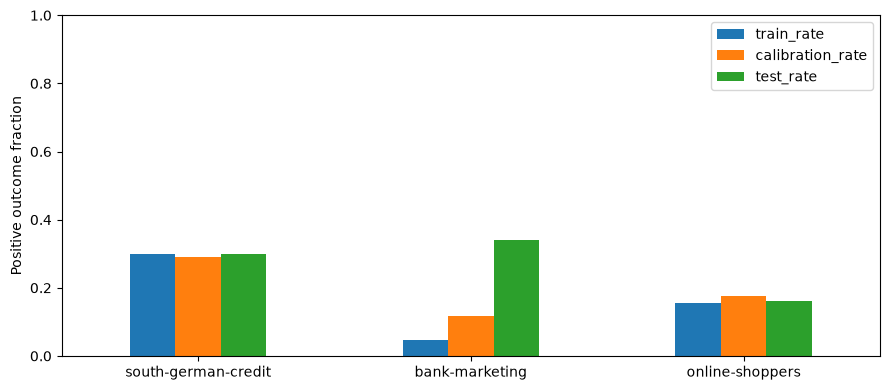

,dataset,source_records,legacy_retained_rows,legacy_excluded_rows,conflicting_feature_groups,rows_in_conflicting_feature_groups,customer_id_available
0,south-german-credit,1000,1000,0,0,0,False
1,bank-marketing,41188,38930,2258,237,542,False
2,online-shoppers,12330,12205,125,0,0,False


In [6]:
# ruff: noqa: E501
datasets = {}
profiles = []
feature_profiles = []
for slug in SOURCES:
    data = load_uci(slug)
    datasets[slug] = data
    X, y, train, cal, test, meta, *_ = data
    profiles.append(
        {
            "dataset": slug,
            "source_rows": meta["raw_rows"],
            "audited_source_rows": len(X),
            "historically_excluded_rows": meta["removed_duplicate_or_conflicting_rows"],
            "conflicting_groups": meta["conflicting_feature_groups"],
            "features": X.shape[1],
            "missing_cells": int(X.isna().sum().sum()),
            "train_n": len(train),
            "calibration_n": len(cal),
            "test_n": len(test),
            "train_rate": y.loc[train].mean(),
            "calibration_rate": y.loc[cal].mean(),
            "test_rate": y.loc[test].mean(),
        }
    )
    for column in X:
        feature_profiles.append(
            {
                "dataset": slug,
                "feature": column,
                "dtype": str(X[column].dtype),
                "unique_values": X[column].nunique(),
                "missing": X[column].isna().sum(),
                "unknown_values": X[column].astype(str).eq("unknown").sum(),
            }
        )
    assert not (set(train) & set(cal) or set(train) & set(test) or set(cal) & set(test))
    display(Markdown(f"**{slug}: example training inputs and numerical ranges**"))
    display(X.loc[train].head(3))
    display(X.loc[train].describe(include="number").T)
eda = pd.DataFrame(profiles)
feature_eda = pd.DataFrame(feature_profiles)
eda.to_csv(RUN / "eda_summary.csv", index=False)
feature_eda.to_csv(RUN / "eda_features.csv", index=False)
display(eda)
display(feature_eda)
ax = eda.set_index("dataset")[["train_rate", "calibration_rate", "test_rate"]].plot.bar(
    figsize=(9, 4), rot=0
)
ax.set(ylabel="Positive outcome fraction", xlabel="", ylim=(0, 1))
plt.tight_layout()
plt.show()


display(
    pd.read_csv(REVISION / "population_summary.csv")[
        [
            "dataset",
            "source_records",
            "legacy_retained_rows",
            "legacy_excluded_rows",
            "conflicting_feature_groups",
            "rows_in_conflicting_feature_groups",
            "customer_id_available",
        ]
    ]
)

### 2.4 Baseline training and model requests

Logistic regression standardizes numerical features and encodes categories. CatBoost uses categorical features directly. Both train only on the training partition. The constant baseline predicts that partition’s positive rate. Each Jev request asks Choice about two outcomes and Noul about each outcome separately; labels remain outside the request payload.

This revision reads those saved baseline predictions and request bodies; it does not retrain models or send requests.


In [7]:
# ruff: noqa: E501
jobs = json.loads((SOURCE / "requests.json").read_text())
baseline = pd.read_csv(SOURCE / "baseline_predictions.csv")
assert len(jobs) == 1045
display(pd.DataFrame(jobs).groupby("experiment").size().rename("historical requests"))
display(jobs[0]["payload"])

experiment
bank-marketing         320
online-shoppers        320
south-german-credit    320
synthetic               63
two-dice                22
Name: historical requests, dtype: int64

{'state': 'A coin comes up heads 0% of the time and tails 100% of the time. Flips are independent. The next flip has not happened.',
 'model': 'jev-1.13.0',
 'questions': {'choice': {'type': 'choice',
   'instructions': 'Which of these outcomes will occur on the next random trial?',
   'criteria': {'heads': 'The next coin flip comes up heads.',
    'tails': 'The next coin flip comes up tails.'}},
  'event': {'type': 'noul',
   'instructions': 'The next coin flip comes up heads.'},
  'complement': {'type': 'noul',
   'instructions': 'The next coin flip comes up tails.'}}}

In [8]:
# ruff: noqa: E501
records, validation, request_coverage = load_cached_run(SOURCE)
display(request_coverage)
display(
    {
        "valid_probability_rows": int(validation.all_probabilities_valid.sum()),
        "normalized_choice_rows": int(validation.choice_normalized.sum()),
        "noul_complement_incoherence_gt_1e_5": int((validation.noul_complement_gap > 1e-5).sum()),
    }
)
# Complement disagreement is diagnosed, not silently normalized or excluded.
display(pd.read_csv(REVISION / "dice_coherence.csv"))
records.to_csv(RUN / "all_predictions.csv", index=False)
validation.to_csv(RUN / "validation_checks.csv", index=False)

{'requested_calls': 1045,
 'saved_responses': 1045,
 'missing_responses': 0,
 'failure_log_entries': 0,
 'repeated_payload_calls': 0,
 'new_api_calls': 0,
 'full_raw_response_validation': 'unavailable; saved selected fields only'}

{'valid_probability_rows': 1045,
 'normalized_choice_rows': 1045,
 'noul_complement_incoherence_gt_1e_5': 1028}

,track,interface,separate_binary_questions,probability_sum,sum_minus_one,normalization_required_for_binary_scoring
0,explicit,Choice,11,0.47,-0.53,False
1,explicit,Noul,11,1.03,0.03,False
2,parameters,Choice,11,0.42,-0.58,False
3,parameters,Noul,11,1.44,0.44,False


### 2.5 Calibration, Monte Carlo simulation, and scoring

The historical correction fits an intercept and slope on 120 reserved labels, then scores 200 separate pilot test records whose results have already been inspected. Monte Carlo simulation draws 500 sets of 2,000 outcomes per synthetic case; dice use joint counts so every roll contributes to exactly one sum. A paired bootstrap resamples test records 1,000 times to estimate Brier-score intervals and changes. These intervals do not include uncertainty from retraining or repeated model queries.

Revised results prioritize probability MAE and excess expected Brier for exact probabilities. Proper scores, calibration diagnostics, discrimination, and coverage remain separate. An oracle has zero recovery error and expected Brier `mean(q*(1-q))`; the controls below also test constant and rank-preserving overconfident predictors. Revised intervals include paired Choice-versus-Noul comparisons and both fixed-calibrator and calibration-refit uncertainty.


In [9]:
# ruff: noqa: E501
def decompose(probabilities, event_rates, bins=10):
    """Return components for forecasts replaced by bin means, plus raw-score residual.

    event_rates may be binary labels or known Bernoulli probabilities. The latter
    yields conditional expected scores, not a finite-label calibration estimate.
    """
    p, q = np.asarray(probabilities, dtype=float), np.asarray(event_rates, dtype=float)
    if p.ndim != 1 or q.shape != p.shape or not len(p):
        raise ValueError("Use equally sized nonempty vectors.")
    if type(bins) is not int or bins < 1:
        raise ValueError("bins must be a positive integer.")
    if not (np.isfinite(p).all() and np.isfinite(q).all()):
        raise ValueError("Values must be finite.")
    if not (((p >= 0) & (p <= 1)).all() and ((q >= 0) & (q <= 1)).all()):
        raise ValueError("Values must lie in [0, 1].")
    ids = np.minimum((p * bins).astype(int), bins - 1)
    mean_rate = q.mean()
    uncertainty = mean_rate * (1 - mean_rate)
    reliability = resolution = 0.0
    grouped_p = np.empty_like(p)
    for b in np.unique(ids):
        mask = ids == b
        weight = mask.mean()
        pb, qb = p[mask].mean(), q[mask].mean()
        grouped_p[mask] = pb
        reliability += weight * (pb - qb) ** 2
        resolution += weight * (qb - mean_rate) ** 2
    raw_brier = np.mean(q * (1 - q) + (p - q) ** 2)
    grouped_brier = np.mean(q * (1 - q) + (grouped_p - q) ** 2)
    return {
        "bins": bins,
        "n": len(p),
        "event_rate": float(mean_rate),
        "uncertainty": float(uncertainty),
        "reliability": float(reliability),
        "resolution": float(resolution),
        "normalized_reliability": float(reliability / uncertainty) if uncertainty else None,
        "raw_brier": float(raw_brier),
        "grouped_brier": float(grouped_brier),
        "binning_residual": float(raw_brier - grouped_brier),
    }

In [10]:
# ruff: noqa: E501
def evaluate(rows: list[dict], *, trials: int = 2000, repetitions: int = 500, seed: int = 42):
    """MC ranges are conditional on the fixed scenarios and cached predictions."""
    if not rows:
        return pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
    if trials < 1 or repetitions < 2:
        raise ValueError("Use positive trials and at least two repetitions.")
    frame = pd.DataFrame(rows)
    q = frame.q.to_numpy(float)
    rng = np.random.default_rng(seed)
    counts = rng.binomial(trials, q, size=(repetitions, len(q)))
    details, summaries, reliability = [], [], []
    for primitive in ["choice", "noul"]:
        p = frame[f"{primitive}_p"].to_numpy(float)
        if not (np.isfinite(p).all() and ((0 <= p) & (p <= 1)).all()):
            raise ValueError("Probabilities must be finite and in [0, 1].")
        # xlogy(0, 0)=0; genuinely impossible predictions incur infinite log loss.
        expected_nll = -xlogy(q, p) - xlogy(1 - q, 1 - p)
        expected_brier = (p - q) ** 2 + q * (1 - q)
        observed_rates = counts / trials
        sampled_nll = -xlogy(observed_rates, p) - xlogy(1 - observed_rates, 1 - p)
        sampled_brier = observed_rates * (1 - p) ** 2 + (1 - observed_rates) * p**2
        eps = 1e-12
        clipped = np.clip(p, eps, 1 - eps)
        detail = frame[["scenario_id", "family", "track", "q"]].copy()
        detail["primitive"] = primitive
        detail["p"] = p
        detail["absolute_probability_error"] = abs(p - q)
        detail["expected_brier"] = expected_brier
        detail["expected_nll"] = expected_nll
        detail["clipped_expected_nll_eps_1e12"] = -xlogy(q, clipped) - xlogy(1 - q, 1 - clipped)
        detail["oracle_expected_brier"] = q * (1 - q)
        detail["oracle_expected_nll"] = -xlogy(q, q) - xlogy(1 - q, 1 - q)
        detail["mc_mean_event_rate"] = observed_rates.mean(axis=0)
        details.append(detail)
        for track in frame.track.unique():
            mask = (frame.track == track).to_numpy()
            replicate_brier = sampled_brier[:, mask].mean(axis=1)
            summaries.append(
                {
                    "primitive": primitive,
                    "track": track,
                    "scenarios": int(mask.sum()),
                    "probability_mae": float(abs(p[mask] - q[mask]).mean()),
                    "expected_brier": float(expected_brier[mask].mean()),
                    "expected_nll": float(expected_nll[mask].mean()),
                    "infinite_nll_scenarios": int(np.isinf(expected_nll[mask]).sum()),
                    "mc_brier_mean": float(replicate_brier.mean()),
                    "mc_brier_mean_se": float(replicate_brier.std(ddof=1) / np.sqrt(repetitions)),
                    "mc_brier_p025": float(np.quantile(replicate_brier, 0.025)),
                    "mc_brier_p975": float(np.quantile(replicate_brier, 0.975)),
                    "mc_nll_mean": float(sampled_nll[:, mask].mean()),
                }
            )
            bins = np.minimum((p * 10).astype(int), 9)
            oracle_ece = 0.0
            mc_ece = np.zeros(repetitions)
            for bin_id in range(10):
                selected = mask & (bins == bin_id)
                if not selected.any():
                    continue
                rates = observed_rates[:, selected].mean(axis=1)
                weight = selected.sum() / mask.sum()
                oracle_ece += weight * abs(p[selected].mean() - q[selected].mean())
                mc_ece += weight * abs(p[selected].mean() - rates)
                reliability.append(
                    {
                        "primitive": primitive,
                        "track": track,
                        "bin": bin_id,
                        "scenarios": int(selected.sum()),
                        "mean_prediction": float(p[selected].mean()),
                        "oracle_event_rate": float(q[selected].mean()),
                        "mc_event_rate": float(rates.mean()),
                        "mc_p025": float(np.quantile(rates, 0.025)),
                        "mc_p975": float(np.quantile(rates, 0.975)),
                    }
                )
            summaries[-1]["oracle_binned_ece_10"] = float(oracle_ece)
            summaries[-1]["mc_ece_mean_10"] = float(mc_ece.mean())
    return pd.concat(details, ignore_index=True), pd.DataFrame(summaries), pd.DataFrame(reliability)

In [11]:
# ruff: noqa: E501
METHODS = [
    "Choice",
    "Noul",
    "Choice corrected",
    "Noul corrected",
    "Logistic regression",
    "CatBoost",
    "Constant",
]


def scores(p, target, *, target_kind="real_event"):
    return evaluate_predictions(p, target, target_kind=target_kind)


q_control = np.array([0.1, 0.3, 0.5, 0.7, 0.9])
oracle = scores(q_control, q_control, target_kind="known_probability")
assert oracle["probability_mae"] == oracle["excess_expected_brier"] == 0
assert np.isclose(oracle["expected_brier"], np.mean(q_control * (1 - q_control)))
display(
    pd.read_csv(REVISION / "controlled_predictors.csv")[
        [
            "predictor",
            "target_kind",
            "brier",
            "probability_mae",
            "excess_expected_brier",
            "ece10",
            "auroc",
        ]
    ]
)

,predictor,target_kind,brier,probability_mae,excess_expected_brier,ece10,auroc
0,Oracle,known_probability,0.170000,0.000000,0.000000,0.000000,NaN
1,Constant base rate,known_probability,0.250000,0.240000,0.080000,0.000000,NaN
2,Overconfident rank-preserving,known_probability,0.194508,0.130263,0.024508,0.130263,NaN
3,Constant observed balanced (AUROC=.5),real_event,0.250000,NaN,NaN,0.000000,0.5


In [12]:
# ruff: noqa: E501
# Preserve the original results as a filtered-population sensitivity analysis.
metrics = pd.read_csv(SOURCE / "uci_metrics.csv")
test_frames = [pd.read_csv(SOURCE / f"{slug}-test-predictions.csv") for slug in SOURCES]
for frame in test_frames:
    slug = frame.dataset.iloc[0]
    _, y, _, _, _, _ = datasets[slug]
    assert np.array_equal(frame.y.to_numpy(), y.loc[frame.row_id].to_numpy())
revised_metrics = pd.read_csv(REVISION / "metrics.csv")
paired = pd.read_csv(REVISION / "paired_comparisons.csv")
calibration_bins = pd.read_csv(REVISION / "reliability_bins.csv")
ece_sensitivity = pd.read_csv(REVISION / "ece_sensitivity.csv")
# New corrections and their uncertainty were fit only on the saved calibration records.
# Numerical fitting uses eps=1e-6; slope correction uses identity-centered ridge lambda=1.
# All arms/settings were fixed for the exploratory reanalysis, without test tuning.
calibration = pd.read_csv(REVISION / "calibrator_fits.csv")

In [13]:
# ruff: noqa: E501
# Historical conditional outcome simulations; no additional model evaluations.
detail = pd.read_csv(SOURCE / "synthetic_scenario_metrics.csv")
synth_summary = pd.read_csv(SOURCE / "synthetic_summary.csv")
reliability = pd.read_csv(SOURCE / "synthetic_reliability.csv")
dice_summary = pd.read_csv(SOURCE / "dice_summary.csv")
# Exact-q probability MAE/excess expected Brier and grouped uncertainty are shown below.

In [14]:
# ruff: noqa: E501
CONDITIONS = [
    "Coin toss · probability supplied",
    "Threshold events · probability supplied",
    "Threshold events · distribution described",
    "Two dice · probability supplied",
    "Two dice · dice description",
    "South German Credit",
    "Bank Marketing",
    "Online Shoppers",
]
COLORS = {"Choice": "#0072B2", "Noul": "#D55E00"}


def compare_experiments(records, test_frames):
    """Compute the same metrics and bins using q for known events or y for observations."""
    panels = []
    for label, family, track in [
        (CONDITIONS[0], "bernoulli", "explicit"),
        (CONDITIONS[1], "other", "explicit"),
        (CONDITIONS[2], "other", "parameters"),
        (CONDITIONS[3], "two_dice", "explicit"),
        (CONDITIONS[4], "two_dice", "parameters"),
    ]:
        mask = (
            records.family.eq(family)
            if family != "other"
            else records.experiment.eq("synthetic") & records.family.ne("bernoulli")
        )
        frame = records[mask & records.track.eq(track)]
        panels.append(
            (
                label,
                "Known probability",
                frame.q.to_numpy(),
                {"Choice": frame.choice_p.to_numpy(), "Noul": frame.noul_p.to_numpy()},
            )
        )
    for label, slug in zip(
        CONDITIONS[5:], ["south-german-credit", "bank-marketing", "online-shoppers"], strict=True
    ):
        frame = next(t for t in test_frames if t.dataset.iloc[0] == slug)
        panels.append(
            (
                label,
                "Observed outcome",
                frame.y.to_numpy(),
                {
                    method: frame[method].to_numpy()
                    for method in [
                        "Choice",
                        "Noul",
                        "Choice corrected",
                        "Noul corrected",
                        "Logistic regression",
                        "CatBoost",
                        "Constant",
                    ]
                },
            )
        )
    summary, curves = [], []
    for label, reference, target, forecasts in panels:
        for method, prediction in forecasts.items():
            assert len(target) == len(prediction) and len(target) > 0
            bins = np.minimum((prediction * 10).astype(int), 9)
            ece = 0.0
            for b in np.unique(bins):
                keep = bins == b
                forecast, rate = prediction[keep].mean(), target[keep].mean()
                ece += keep.mean() * abs(forecast - rate)
                curves.append(
                    {
                        "condition": label,
                        "reference": reference,
                        "method": method,
                        "bin": int(b),
                        "n": int(keep.sum()),
                        "forecast": forecast,
                        "target": rate,
                    }
                )
            components = decompose(prediction, target)
            summary.append(
                {
                    "condition": label,
                    "reference": reference,
                    "method": method,
                    "n": len(target),
                    "brier": np.mean(target * (1 - target) + (prediction - target) ** 2),
                    "ece10": ece,
                    "normalized_reliability": components["normalized_reliability"],
                    "mean_forecast": prediction.mean(),
                    "reference_rate": target.mean(),
                }
            )
    return pd.DataFrame(summary), pd.DataFrame(curves)


def comparison_table(summary):
    rows = []
    for condition in CONDITIONS:
        group = summary[summary.condition.eq(condition)].set_index("method")
        rows.append(
            {
                "Experiment / input": condition,
                "Cases": int(group.loc["Choice", "n"]),
                "Reference": group.loc["Choice", "reference"],
                "Choice Brier": group.loc["Choice", "brier"],
                "Noul Brier": group.loc["Noul", "brier"],
                "Choice ECE (pp)": 100 * group.loc["Choice", "ece10"],
                "Noul ECE (pp)": 100 * group.loc["Noul", "ece10"],
            }
        )
    return pd.DataFrame(rows)


unified_metrics, pilot_calibration_bins = compare_experiments(records, test_frames)
unified_metrics.to_csv(RUN / "unified_metrics.csv", index=False)
pilot_calibration_bins.to_csv(RUN / "unified_calibration_bins.csv", index=False)

In [15]:
# ruff: noqa: E501
def comparison_figure(summary, run):
    fig, axes = plt.subplots(1, 3, figsize=(14, 7.5), sharey=True)
    y = np.arange(len(CONDITIONS))
    for method, offset in [("Choice", -0.12), ("Noul", 0.12)]:
        group = summary[summary.method.eq(method)].set_index("condition").loc[CONDITIONS]
        for ax, metric, scale, label in zip(
            axes,
            ["brier", "ece10", "normalized_reliability"],
            [1, 100, 1],
            [
                "Brier score",
                "Calibration gap: ECE (percentage points)",
                "Normalized calibration penalty",
            ],
            strict=True,
        ):
            ax.scatter(scale * group[metric], y + offset, color=COLORS[method], label=method, s=45)
            ax.set(xlabel=label, xlim=(0, None))
            ax.grid(axis="x", alpha=0.2)
            ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_yticks(y, CONDITIONS)
    axes[0].invert_yaxis()
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2, bbox_to_anchor=(0.65, 0.95))
    fig.suptitle("All experiments · raw Jev scores · lower is better", fontsize=14)
    fig.tight_layout(rect=(0, 0, 1, 0.90))
    fig.savefig(run / "main_comparison.png", dpi=160)
    fig.savefig(run / "main_comparison.pdf")
    plt.close(fig)


def calibration_figure(curves, run):
    fig, axes = plt.subplots(4, 2, figsize=(11, 17), sharex=True, sharey=True)
    for ax, condition in zip(axes.flat, CONDITIONS, strict=True):
        frame = curves[curves.condition.eq(condition)]
        for method in ["Choice", "Noul", "Choice corrected", "Noul corrected"]:
            group = frame[frame.method.eq(method)].sort_values("forecast")
            if group.empty:
                continue
            base = method.split(" corrected")[0]
            ax.plot(
                group.forecast,
                group.target,
                "--" if "corrected" in method else "-",
                color=COLORS[base],
                label=method,
            )
            ax.scatter(
                group.forecast,
                group.target,
                s=12 + group.n / group.n.sum() * 100,
                color=COLORS[base],
                alpha=0.75,
            )
        ax.plot([0, 1], [0, 1], "k:", label="Perfect agreement")
        reference = frame.reference.iloc[0]
        ax.set(
            title=condition + "\n" + reference,
            xlim=(0, 1),
            ylim=(0, 1),
            xlabel="Mean predicted probability",
            ylabel="Mean reference probability / outcome",
        )
        ax.grid(alpha=0.15)
        ax.tick_params(labelbottom=True, labelleft=True)
    handles, labels = axes.flat[-1].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.965))
    fig.savefig(run / "calibration_overview.png", dpi=160)
    fig.savefig(run / "calibration_overview.pdf")
    plt.close(fig)


comparison_figure(unified_metrics, RUN)
calibration_figure(pilot_calibration_bins, RUN)

In [16]:
# ruff: noqa: E501
pilot_notebook = nbformat.read(PILOT_NOTEBOOK, as_version=4)
pilot_sections = []
for cell in pilot_notebook.cells:
    for output in cell.get("outputs", []):
        text = output.get("data", {}).get("text/markdown")
        if text is not None:
            pilot_sections.append(text if isinstance(text, str) else "".join(text))

In [17]:
# ruff: noqa: E501
report_cells = nbformat.v4.new_notebook(
    cells=[nbformat.v4.new_markdown_cell(text) for text in pilot_sections]
)
for cell in report_cells.cells:
    if cell.source.startswith("## 4. Discussion"):
        cell.source = cell.source.replace(
            "A duplicate-preserving grouped-split sensitivity check remains needed.",
            "The revised population audit preserves repeated observations and conflicting outcomes, "
            "but full-population Jev evaluation requires predictions absent from this cache.",
        )
        cell.source += (
            "\n\nRevised group/block intervals accompany the original pilot estimates. Feature hashes "
            "are proxies with unknown customer independence; Bank uses 10 adjacent sampled records "
            "per block (5/20 sensitivity), assuming local dependence and independent calibration/test "
            "resampling. They do not repair temporal shift. Related synthetic prompts/questions stay "
            "in the same generating group; one dice process cannot supply a population interval. "
            "Refit intervals include calibration-sample uncertainty, while fixed-fit intervals do not; "
            "both condition on baseline training and prompts. Bootstrap does not eliminate ECE bias. "
            "The [methodological audit](../methodology-audit.md) distinguishes checked findings from "
            "assumptions. The separate [frozen-protocol draft](../confirmatory-protocol.md) specifies "
            "comparisons, effect sizes, tolerances, exclusions, sample sizes/rare-event gates, untouched "
            "temporal/domain cohorts and templates, and support/contradict/inconclusive criteria. "
            "Its acquisition/model lock and new data are still required; reshuffling this pilot is "
            "not independent confirmation."
        )
    elif cell.source.startswith("## Appendix: individual experiments"):
        cell.source += (
            "\n\nThe original tables and plots below retain the historical correction and iid, "
            "fixed-fit intervals. Additional tables in the same sections report the revised arms "
            "and group/block uncertainty. All real-data scores concern the filtered sensitivity "
            "sample; excluded observations have no cached predictions."
        )

In [18]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown" and c.source.split("\n", 1)[0] == "## 3. Results"
        )
    )
)

## 3. Results

### 3.1 Key findings

**Noul had lower Brier loss in 7/8 conditions and numerically lower calibration error in 8/8.** The credit ECE difference was only 0.01 percentage point; these are descriptive comparisons, not significance claims. Both comparisons use the same eight rows in the summary table and figures; differences in event rates prevent a pooled ranking.

**Coins and dice expose probability errors directly.** Coin Brier loss was 0.1779 for Choice and 0.1247 for Noul. With only a dice description, it was 0.0916 and 0.0828, respectively. Supplying the exact dice probabilities reduced both losses. On the other distributions, exact probabilities helped Noul but increased Choice loss: supplied probabilities do not ensure faithful scores.

**Real-data calibration remained uneven.** Raw ECE ranged from 9.3 to 40.0 percentage points. Correction reduced the Brier point estimate in 5/6 comparisons but worsened Bank Marketing Noul. The paired interval for Bank Choice included no change. Detailed baseline and correction comparisons appear with each experiment in the appendix.

In [19]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0] == "### 3.2 Summary comparisons"
        )
    )
)

display(
    Markdown(
        "**Revised probability-recovery errors and paired uncertainty** (95% intervals; dice has one generating configuration, so its generalization interval is unavailable)."
    )
)
display(
    revised_metrics[revised_metrics.target_kind.eq("known_probability")][
        [
            "condition",
            "method",
            "probability_mae",
            "probability_mae_low",
            "probability_mae_high",
            "excess_expected_brier",
            "excess_expected_brier_low",
            "excess_expected_brier_high",
        ]
    ]
)
display(
    paired[
        paired.comparison.eq("Noul - Choice")
        & paired.metric.isin(["brier", "excess_expected_brier"])
        & ~paired.uncertainty.isin(["fixed_predictors_block_5", "fixed_predictors_block_20"])
    ][["condition", "metric", "difference", "ci_low", "ci_high", "uncertainty"]]
)

### 3.2 Summary comparisons

The first three rows are variants of one binary-probability experiment: coins, thresholds with probabilities supplied, and thresholds with distributions described. All eight conditions appear in the same order in this table and both figures. Choice and Noul are raw model outputs. Brier loss measures squared forecast error; ECE measures grouped calibration gaps using ten fixed-width probability bins. Lower is better for both. **pp** means percentage points. For known probabilities, Brier is the exact expected loss `mean(q(1−q) + (p−q)²)` and ECE compares grouped forecasts with known `q`. For observed outcomes, the same formulas use binary labels `y`, so Brier reduces to `mean((p−y)²)`. Cases count scenarios in the first five rows and test records in the last three. Compare methods within a row; event rates and task difficulty differ, so no grand average is reported. Recalibration and supervised baselines require training labels and were fitted only for UCI data; their results remain in the experiment appendices.

| Experiment / input | Cases | Reference | Choice Brier | Noul Brier | Choice ECE (pp) | Noul ECE (pp) |
| --- | --- | --- | --- | --- | --- | --- |
| Coin toss · probability supplied | 15 | Known probability | 0.17792 | 0.12472 | 16.80000 | 3.06667 |
| Threshold events · probability supplied | 24 | Known probability | 0.20272 | 0.13879 | 19.74789 | 3.21692 |
| Threshold events · distribution described | 24 | Known probability | 0.16396 | 0.14448 | 11.95001 | 4.14794 |
| Two dice · probability supplied | 11 | Known probability | 0.08382 | 0.08083 | 4.81818 | 0.57576 |
| Two dice · dice description | 11 | Known probability | 0.09165 | 0.08277 | 9.15152 | 4.00000 |
| South German Credit | 200 | Observed outcome | 0.22288 | 0.23278 | 15.85000 | 15.84000 |
| Bank Marketing | 200 | Observed outcome | 0.22226 | 0.19352 | 20.28500 | 9.33000 |
| Online Shoppers | 200 | Observed outcome | 0.31663 | 0.22318 | 39.98500 | 29.30000 |

**Revised probability-recovery errors and paired uncertainty** (95% intervals; dice has one generating configuration, so its generalization interval is unavailable).

,condition,method,probability_mae,probability_mae_low,probability_mae_high,excess_expected_brier,excess_expected_brier_low,excess_expected_brier_high
0,bernoulli/explicit,Choice,0.168000,0.089333,0.246667,0.054947,0.020487,0.092027
1,bernoulli/explicit,Noul,0.036000,0.025333,0.046667,0.001747,0.000927,0.002720
2,thresholds/explicit,Choice,0.200150,0.157271,0.239674,0.065404,0.046230,0.083306
3,thresholds/explicit,Noul,0.032169,0.024476,0.040801,0.001474,0.000837,0.002216
4,thresholds/parameters,Choice,0.120201,0.070934,0.171228,0.026649,0.012441,0.041553
5,thresholds/parameters,Noul,0.066090,0.051117,0.086891,0.007163,0.003762,0.011567
6,two_dice/explicit,Choice,0.048182,NaN,NaN,0.003147,NaN,NaN
7,two_dice/explicit,Noul,0.011414,NaN,NaN,0.000157,NaN,NaN
8,two_dice/parameters,Choice,0.091515,NaN,NaN,0.010981,NaN,NaN
9,two_dice/parameters,Noul,0.040000,NaN,NaN,0.002098,NaN,NaN


,condition,metric,difference,ci_low,ci_high,uncertainty
1,bernoulli/explicit,excess_expected_brier,-0.053200,-0.090273,-0.019080,fixed_predictions_group_bootstrap
2,bernoulli/explicit,brier,-0.053200,-0.090273,-0.019080,fixed_predictions_group_bootstrap
5,thresholds/explicit,excess_expected_brier,-0.063930,-0.081093,-0.045099,fixed_predictions_group_bootstrap
6,thresholds/explicit,brier,-0.063930,-0.081093,-0.045099,fixed_predictions_group_bootstrap
9,thresholds/parameters,excess_expected_brier,-0.019486,-0.036092,-0.002531,fixed_predictions_group_bootstrap
10,thresholds/parameters,brier,-0.019486,-0.036092,-0.002531,fixed_predictions_group_bootstrap
13,two_dice/explicit,excess_expected_brier,-0.002990,NaN,NaN,fixed_predictions_group_bootstrap
14,two_dice/explicit,brier,-0.002990,NaN,NaN,fixed_predictions_group_bootstrap
17,two_dice/parameters,excess_expected_brier,-0.008883,NaN,NaN,fixed_predictions_group_bootstrap
18,two_dice/parameters,brier,-0.008883,NaN,NaN,fixed_predictions_group_bootstrap


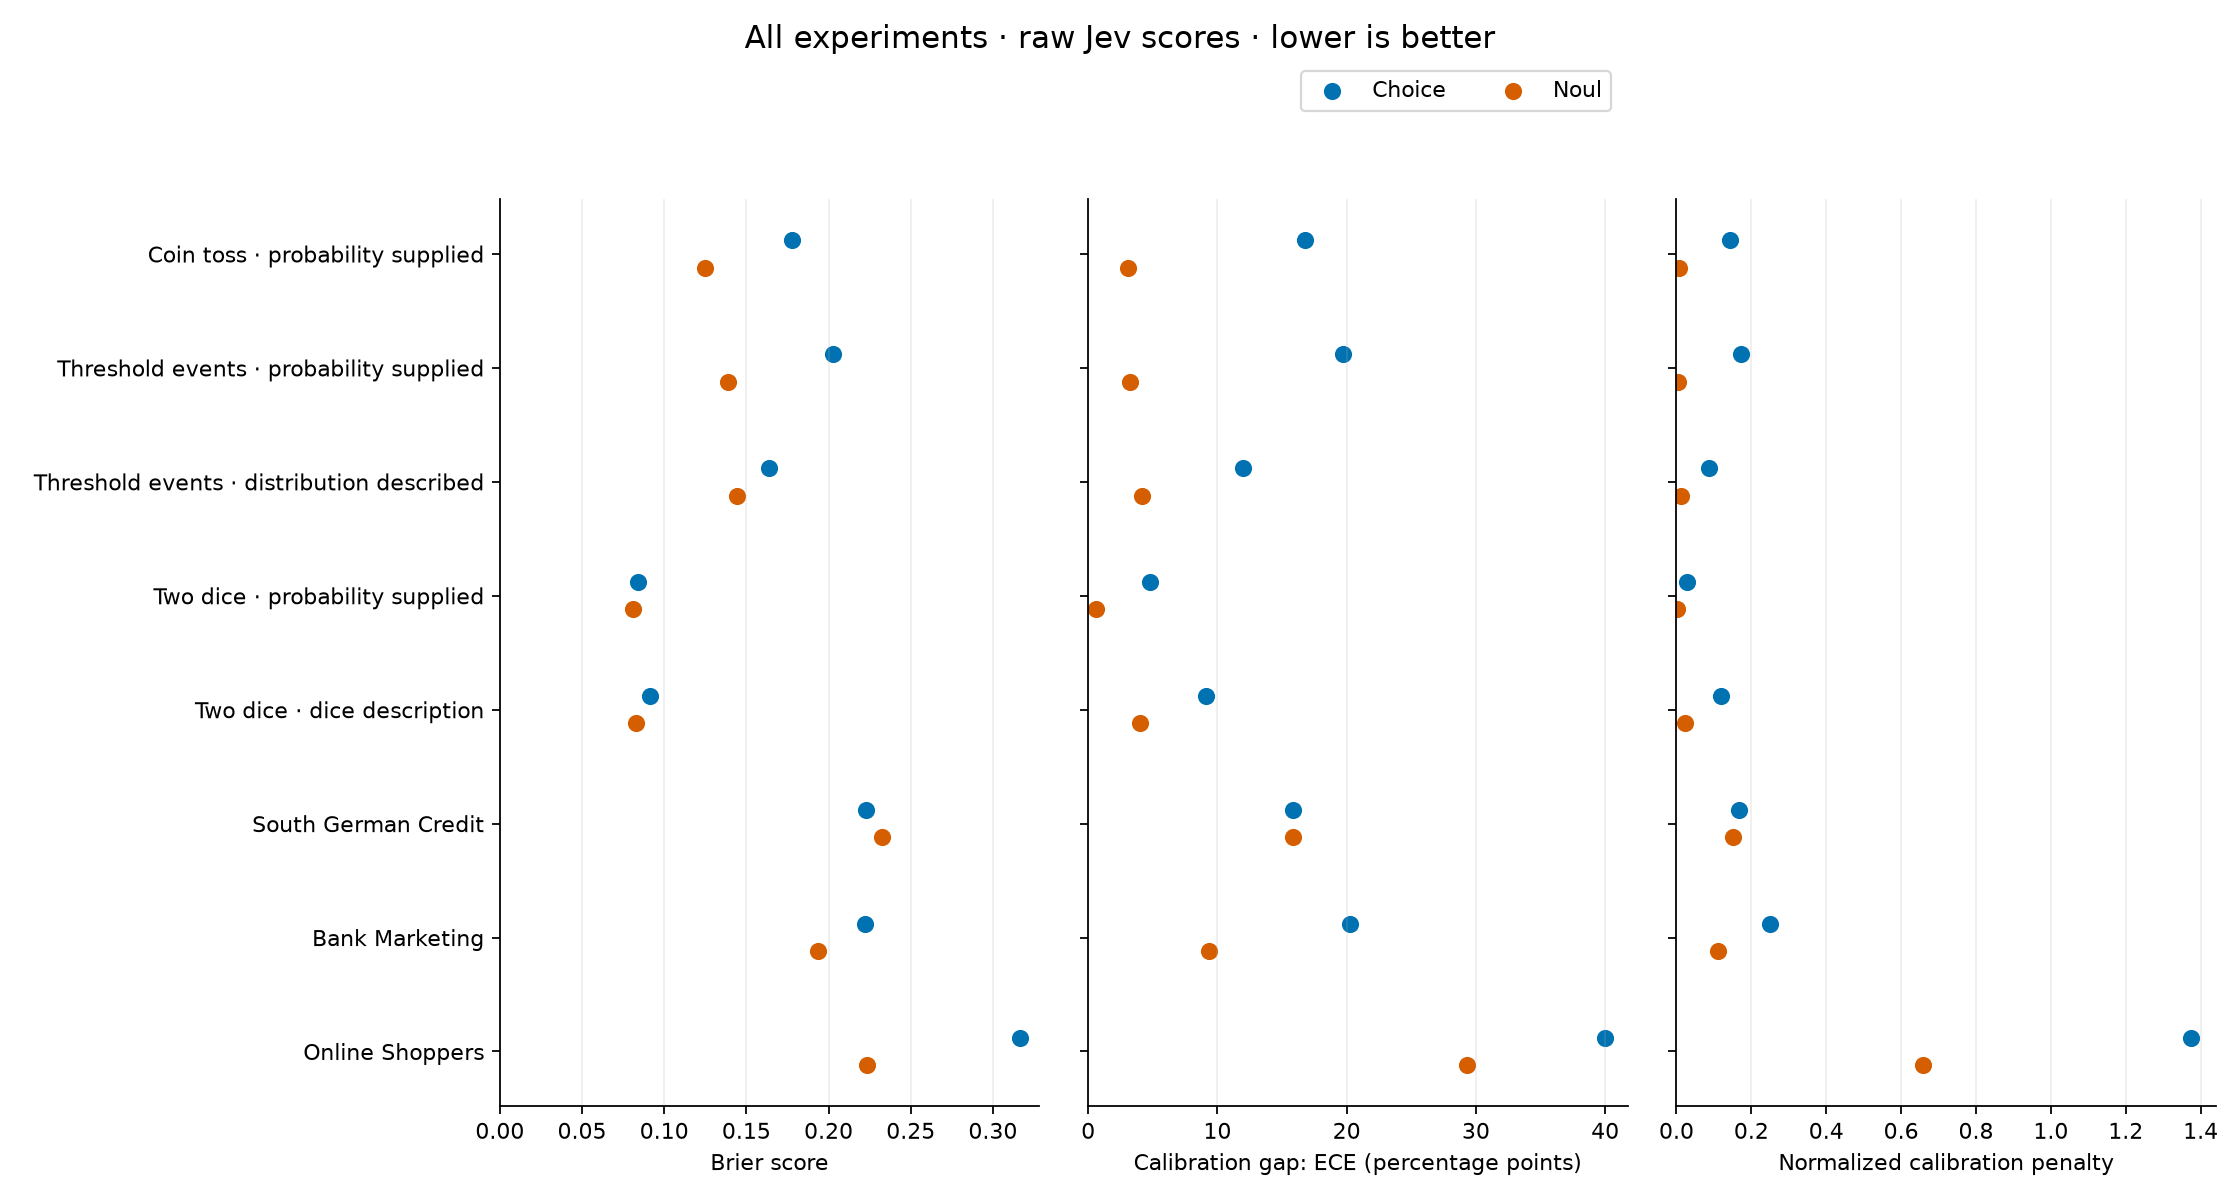

In [20]:
# ruff: noqa: E501
display(Image(filename=str(RUN / "main_comparison.png")))

**Figure 1. Forecast error and calibration across all experiments.** Blue dots show Choice; orange dots show Noul. Columns report Brier loss, Expected Calibration Error (ECE) in percentage points, and the weighted squared calibration gap divided by the reference rate times its complement. Both calibration measures use ten equal-width probability bins. Generated cases use known probabilities; UCI cases use observed test outcomes. Lower values mean less error. Compare interfaces within each row: event rates and task difficulty differ across rows. Low calibration error alone does not establish predictive value.

The figure preserves the pilot point estimates. Probability-recovery errors and revised paired intervals accompany the summary table above; the normalized penalty is retained only for continuity.


### 3.3 Calibration review across all experiments

Read the calibration curves alongside Brier loss: agreement with event rates can coexist with weak discrimination between outcomes.

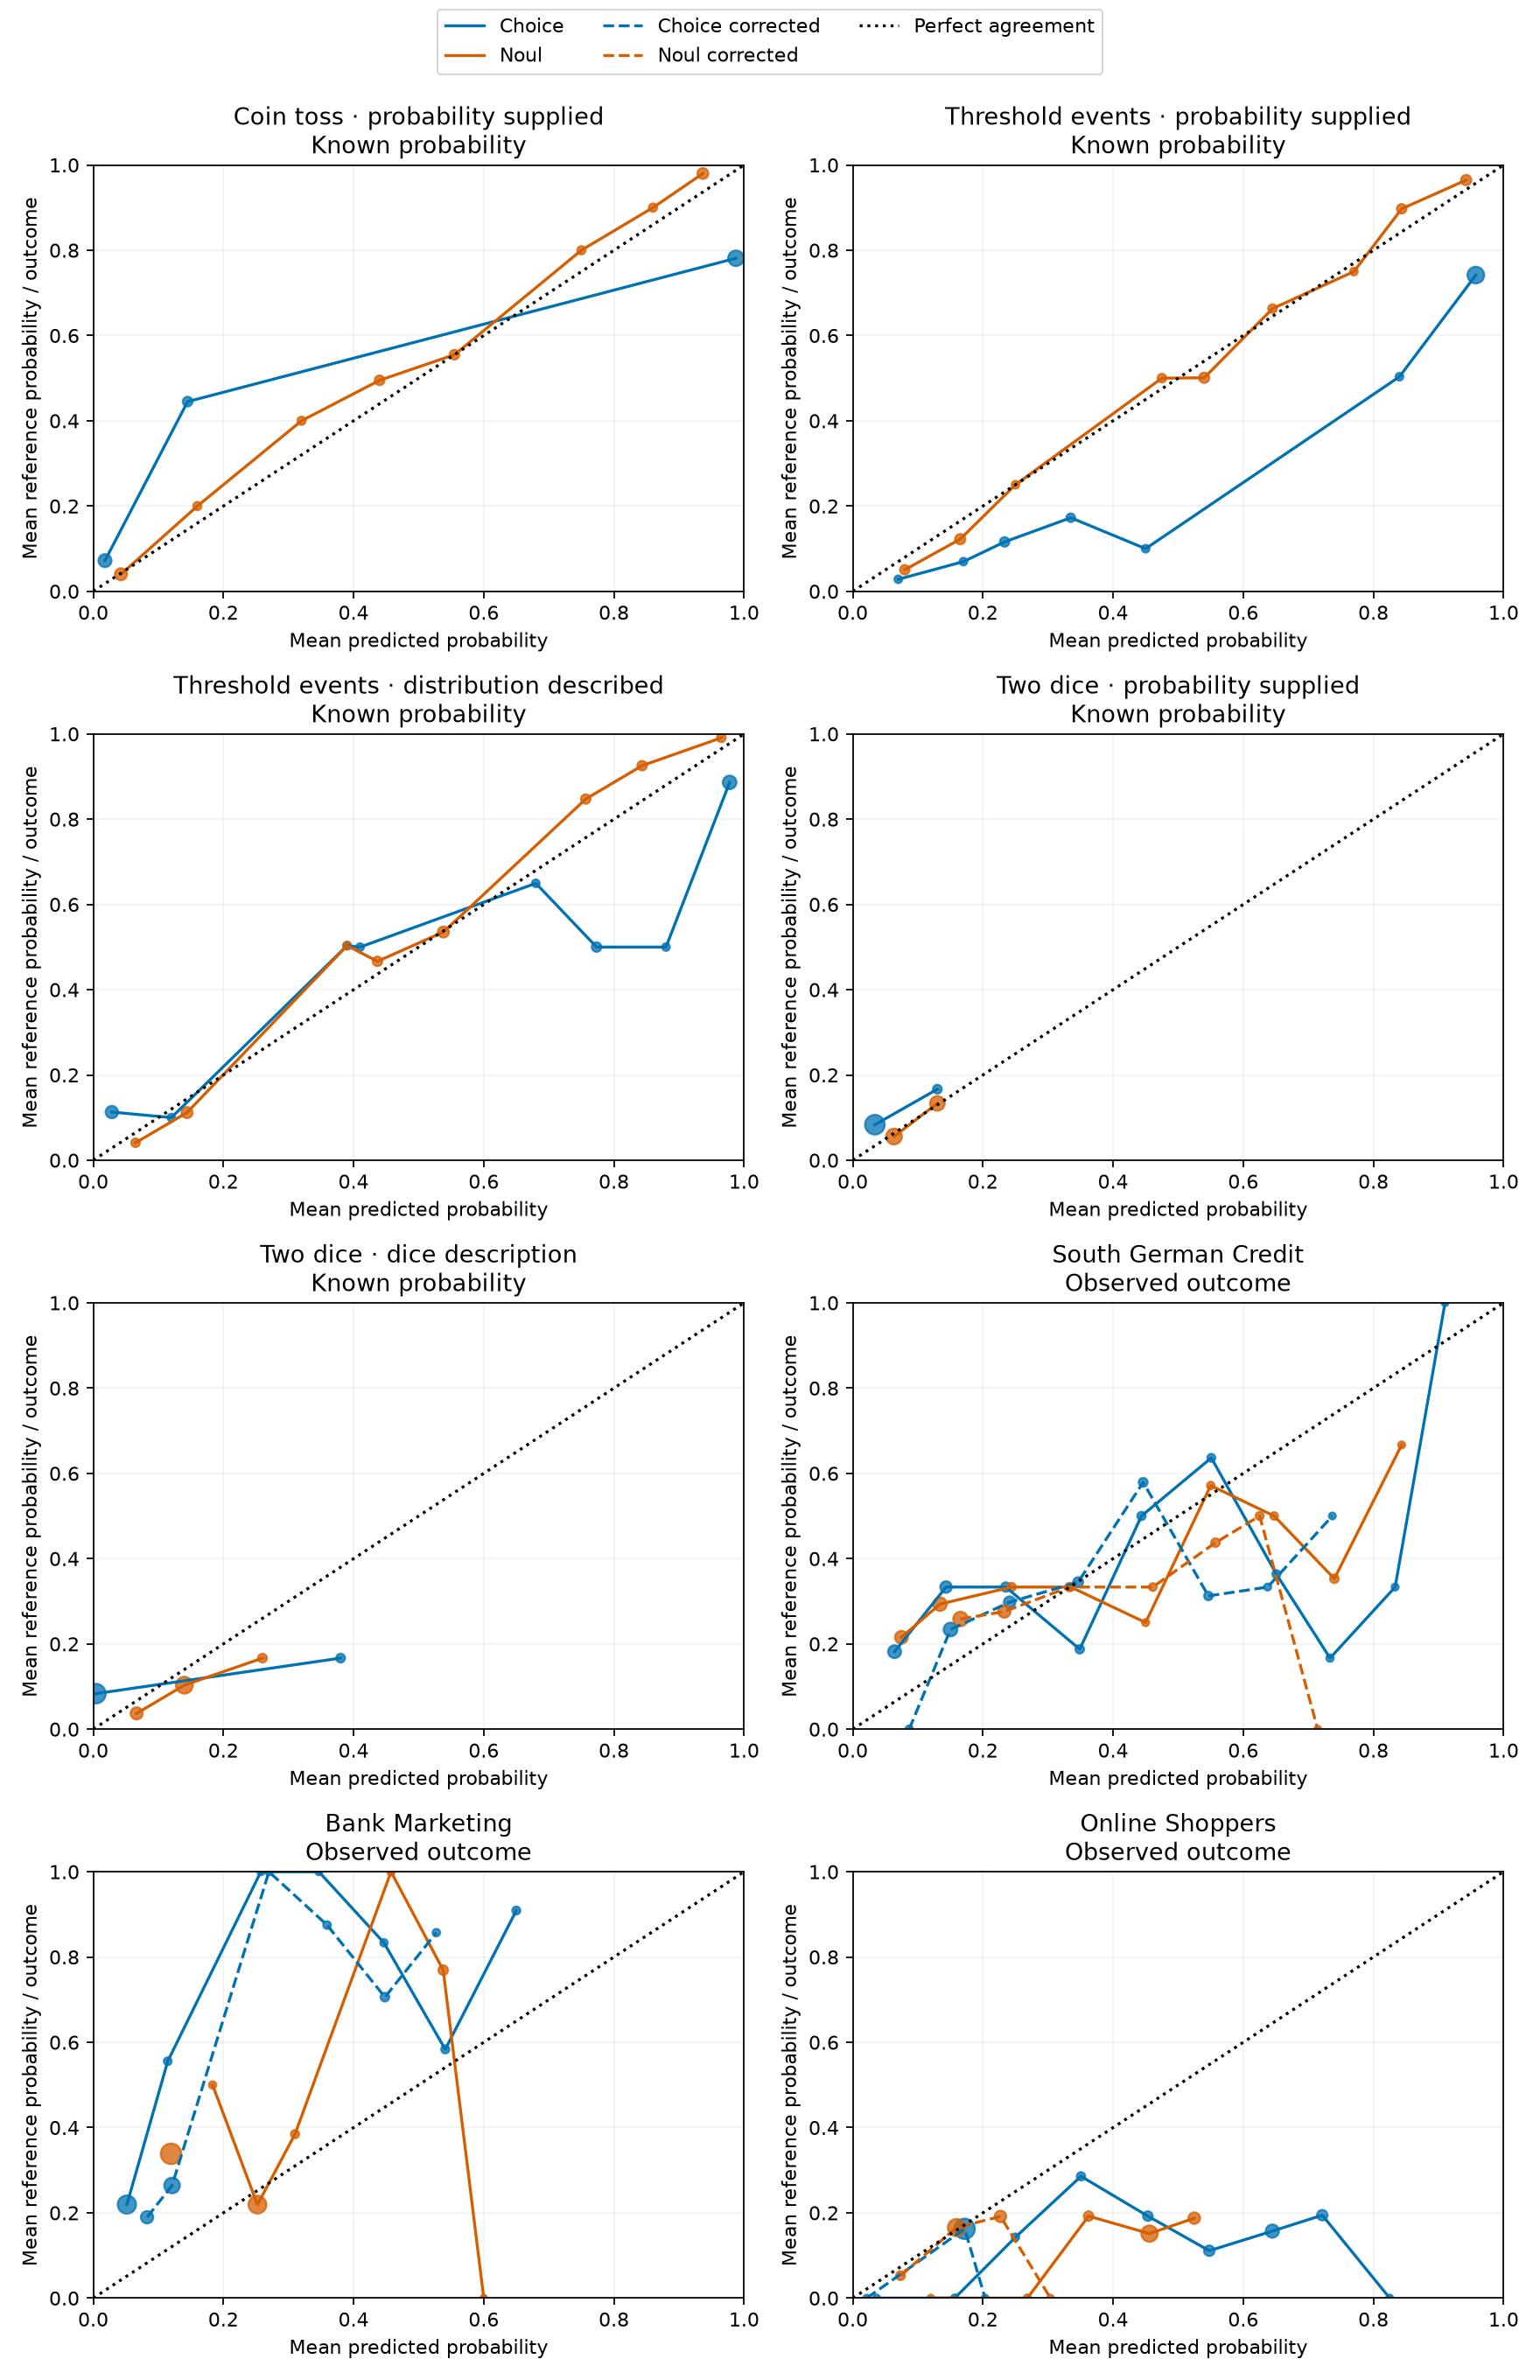

**Revised bin diagnostics.** Ties remain together; ECE intervals re-bin each draw. Bin intervals retain original membership and resample groups/blocks. Blank intervals are unavailable. Full width/mass × 5/10/20 tables are retained in the revised artifacts.

,condition,method,bin,n,n_groups,mean_prediction,mean_target,group_rate_low,group_rate_high
641,south-german-credit,Choice,0,66,66,0.064242,0.181818,0.096774,0.276923
642,south-german-credit,Choice,1,48,48,0.143333,0.333333,0.205128,0.466667
643,south-german-credit,Choice,2,24,24,0.235000,0.333333,0.150000,0.523810
644,south-german-credit,Choice,3,16,16,0.348750,0.187500,0.000000,0.400000
645,south-german-credit,Choice,4,14,14,0.443571,0.500000,0.250000,0.750000
646,south-german-credit,Choice,5,11,11,0.550909,0.636364,0.312500,0.928571
647,south-german-credit,Choice,6,11,11,0.650909,0.363636,0.090909,0.666667
648,south-german-credit,Choice,7,6,6,0.733333,0.166667,0.000000,0.500000
649,south-german-credit,Choice,8,3,3,0.833333,0.333333,0.000000,1.000000
650,south-german-credit,Choice,9,1,1,0.910000,1.000000,NaN,NaN


,condition,method,strategy,requested_bins,occupied_bins,ece,ece_low,ece_high
60,south-german-credit,Choice,equal_width,5,5,0.13400,0.09405,0.20635
61,south-german-credit,Choice,equal_width,10,10,0.15850,0.11105,0.22660
62,south-german-credit,Choice,equal_width,20,19,0.16800,0.13535,0.24415
63,south-german-credit,Choice,equal_mass,5,5,0.12980,0.08245,0.19465
64,south-german-credit,Choice,equal_mass,10,10,0.15380,0.11475,0.22145
65,south-german-credit,Choice,equal_mass,20,19,0.15680,0.14080,0.25145
66,south-german-credit,Noul,equal_width,5,5,0.15680,0.10795,0.22270
67,south-german-credit,Noul,equal_width,10,9,0.15840,0.11735,0.23010
68,south-german-credit,Noul,equal_width,20,17,0.16810,0.13870,0.24885
69,south-german-credit,Noul,equal_mass,5,5,0.16930,0.10925,0.22600


In [21]:
# ruff: noqa: E501
display(Image(filename=str(RUN / "calibration_overview.png")))

display(
    Markdown(
        "**Revised bin diagnostics.** Ties remain together; ECE intervals re-bin each draw. Bin intervals retain original membership and resample groups/blocks. Blank intervals are unavailable. Full width/mass × 5/10/20 tables are retained in the revised artifacts."
    )
)
raw_bins = calibration_bins[
    calibration_bins.target_kind.eq("real_event")
    & calibration_bins.method.isin(["Choice", "Noul"])
    & calibration_bins.strategy.eq("equal_width")
    & calibration_bins.requested_bins.eq(10)
]
display(
    raw_bins[
        [
            "condition",
            "method",
            "bin",
            "n",
            "n_groups",
            "mean_prediction",
            "mean_target",
            "group_rate_low",
            "group_rate_high",
        ]
    ]
)
display(
    ece_sensitivity[
        ece_sensitivity.target_kind.eq("real_event")
        & ece_sensitivity.method.isin(["Choice", "Noul"])
    ][
        [
            "condition",
            "method",
            "strategy",
            "requested_bins",
            "occupied_bins",
            "ece",
            "ece_low",
            "ece_high",
        ]
    ]
)

**Figure 2. Calibration across all experiments.** Panels follow the summary table, read left to right and top to bottom. Each point compares a bin’s mean prediction with its known event probability (generated cases) or observed event rate (UCI records). The dotted diagonal marks agreement; points below it overpredict and points above it underpredict. Blue denotes Choice; orange denotes Noul. Solid lines show raw scores; dashed lines show corrections fitted only on separate UCI calibration records. Larger markers represent a larger share of cases. Lines connect occupied bins; sparse UCI bins are noisy. All panels use ten equal-width bins and identical axes.

The accompanying diagnostics report bin counts and group/block uncertainty, with predeclared equal-width/equal-mass 5/10/20-bin sensitivities. Tied predictions are not split; sparse bins and a single generating group cannot support precise intervals. Bootstrap intervals do not eliminate ECE estimation bias.


In [22]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0] == "## 4. Discussion and limitations"
        )
    )
)

## 4. Discussion and limitations

**Jev is not consistently well calibrated across this study.** The coin and threshold variants share a known binary event probability and the same scoring rule, so they form one experiment with three prompt conditions. The same progression appears in the table and both figures: Noul better recovers stated and derived probabilities, but real-data performance depends on the task. Knowing the input probability makes the synthetic cases tests of probability recovery. The UCI cases test inference from features when the true per-record probability is unknown. Together they probe different failure modes of the same claimed output: a usable event probability.

Brier loss measures overall forecast error; the reliability curves and ECE isolate grouped probability agreement. Good calibration can coexist with little predictive value. On Online Shoppers, corrected forecasts approach the constant baseline; on Bank Marketing, Noul correction worsened on a test sample with a higher event rate. Calibration should therefore be validated on the intended population and any correction tested on separate, representative records.

These are fixed synthetic grids and three 200-record test samples, not a general guarantee or a ranking across tasks. Ten-bin estimates are sensitive to sparse groups. Bootstrap intervals condition on the split and fitted models; they do not account for retraining, prompt variation, or unknown repeated customers. Bank time dependence, historical sampling, and public-data contamination limit generalization. Removing duration created repeated or conflicting Bank feature records; filtering removed 2,258 rows and changed the evaluation population. The revised population audit preserves repeated observations and conflicting outcomes, but full-population Jev evaluation requires predictions absent from this cache.

Revised group/block intervals accompany the original pilot estimates. Feature hashes are proxies with unknown customer independence; Bank uses 10 adjacent sampled records per block (5/20 sensitivity), assuming local dependence and independent calibration/test resampling. They do not repair temporal shift. Related synthetic prompts/questions stay in the same generating group; one dice process cannot supply a population interval. Refit intervals include calibration-sample uncertainty, while fixed-fit intervals do not; both condition on baseline training and prompts. Bootstrap does not eliminate ECE bias. The [methodological audit](../methodology-audit.md) distinguishes checked findings from assumptions. The separate [frozen-protocol draft](../confirmatory-protocol.md) specifies comparisons, effect sizes, tolerances, exclusions, sample sizes/rare-event gates, untouched temporal/domain cohorts and templates, and support/contradict/inconclusive criteria. Its acquisition/model lock and new data are still required; reshuffling this pilot is not independent confirmation.

In [23]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0] == "## Appendix: individual experiments"
        )
    )
)

## Appendix: individual experiments

The following tables and charts report each experiment in detail. Brier p025/p975 give central 95% bootstrap intervals; paired change is corrected minus raw loss. Negative changes indicate improvement. Oracle loss uses the true synthetic probabilities.


The original tables and plots below retain the historical correction and iid, fixed-fit intervals. Additional tables in the same sections report the revised arms and group/block uncertainty. All real-data scores concern the filtered sensitivity sample; excluded observations have no cached predictions.

In [24]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0] == "### Appendix A. Binary probability tests"
        )
    )
)

### Appendix A. Binary probability tests

#### Coin-toss variant

We described independent coin tosses with heads probabilities 0, .01, .05, .10, .20, .40, .49, .50, .51, .60, .80, .90, .95, .99, and 1. Choice selected heads versus tails; Noul separately scored heads and tails. The target was the next outcome, not which outcome was most likely. Each probability generated one request with three questions.

**All 15 recorded cases:**

| q | choice_p | noul_p | complement_p |
| --- | --- | --- | --- |
| 0.00000 | 0.00000 | 0.01000 | 0.97000 |
| 0.01000 | 0.01000 | 0.03000 | 0.95000 |
| 0.05000 | 0.02000 | 0.05000 | 0.91000 |
| 0.10000 | 0.02000 | 0.08000 | 0.86000 |
| 0.20000 | 0.04000 | 0.16000 | 0.75000 |
| 0.40000 | 0.12000 | 0.32000 | 0.61000 |
| 0.49000 | 0.17000 | 0.42000 | 0.53000 |
| 0.50000 | 0.93000 | 0.46000 | 0.45000 |
| 0.51000 | 0.98000 | 0.53000 | 0.42000 |
| 0.60000 | 0.99000 | 0.58000 | 0.33000 |
| 0.80000 | 1.00000 | 0.75000 | 0.16000 |
| 0.90000 | 1.00000 | 0.86000 | 0.10000 |
| 0.95000 | 1.00000 | 0.90000 | 0.06000 |
| 0.99000 | 1.00000 | 0.94000 | 0.05000 |
| 1.00000 | 1.00000 | 0.97000 | 0.01000 |

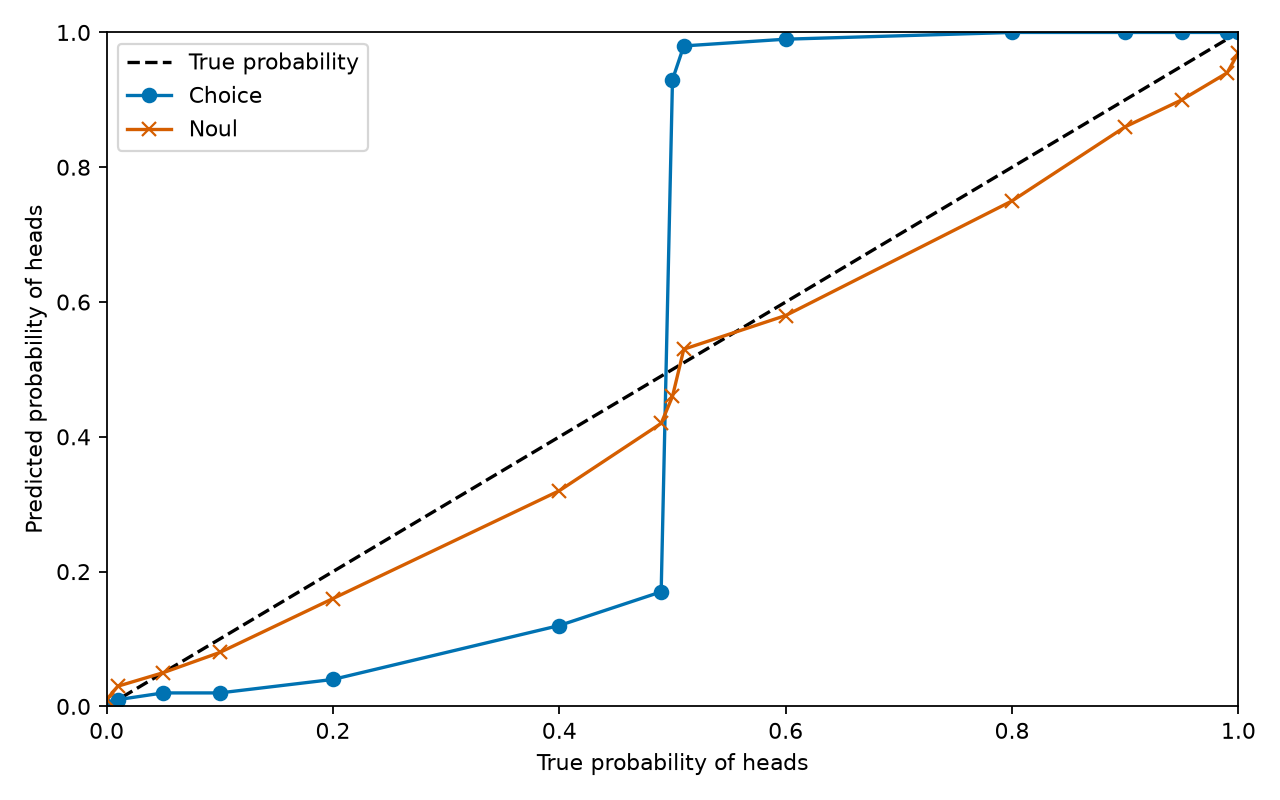

In [25]:
# ruff: noqa: E501
display(Image(filename=str(SOURCE / "coin_predictions.png")))

In [26]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0]
            == "**Figure A1. Coin probability recovery.** The diagonal is exact recovery; points show Jev predictions for each stated heads probability."
        )
    )
)

**Figure A1. Coin probability recovery.** The diagonal is exact recovery; points show Jev predictions for each stated heads probability.

**Exact request body:**

```json
{
  "state": "A coin comes up heads 60% of the time and tails 40% of the time. Flips are independent. The next flip has not happened.",
  "model": "jev-1.13.0",
  "questions": {
    "choice": {
      "type": "choice",
      "instructions": "Which of these outcomes will occur on the next random trial?",
      "criteria": {
        "heads": "The next coin flip comes up heads.",
        "tails": "The next coin flip comes up tails."
      }
    },
    "event": {
      "type": "noul",
      "instructions": "The next coin flip comes up heads."
    },
    "complement": {
      "type": "noul",
      "instructions": "The next coin flip comes up tails."
    }
  }
}
```

**Recorded output fields** (selected from the response; not its full raw body):

```json
{
  "choice_p": 0.99,
  "noul_p": 0.58,
  "complement_p": 0.33
}
```

In [27]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0] == "#### Distribution-threshold variants"
        )
    )
)

#### Distribution-threshold variants

| family | track | primitive | absolute_probability_error | expected_brier | oracle_expected_brier |
| --- | --- | --- | --- | --- | --- |
| binomial | explicit | choice | 0.1102 | 0.1124 | 0.0856 |
| binomial | explicit | noul | 0.0233 | 0.0861 | 0.0856 |
| binomial | parameters | choice | 0.0190 | 0.0860 | 0.0856 |
| binomial | parameters | noul | 0.0733 | 0.0966 | 0.0856 |
| exponential | explicit | choice | 0.1972 | 0.1841 | 0.1278 |
| exponential | explicit | noul | 0.0505 | 0.1304 | 0.1278 |
| exponential | parameters | choice | 0.0528 | 0.1324 | 0.1278 |
| exponential | parameters | noul | 0.1295 | 0.1482 | 0.1278 |
| lognormal | explicit | choice | 0.2067 | 0.1866 | 0.1172 |
| lognormal | explicit | noul | 0.0308 | 0.1182 | 0.1172 |
| lognormal | parameters | choice | 0.0492 | 0.1206 | 0.1172 |
| lognormal | parameters | noul | 0.0675 | 0.1232 | 0.1172 |
| normal | explicit | choice | 0.2300 | 0.2520 | 0.1723 |
| normal | explicit | noul | 0.0176 | 0.1729 | 0.1723 |
| normal | parameters | choice | 0.1958 | 0.2151 | 0.1723 |
| normal | parameters | noul | 0.0500 | 0.1757 | 0.1723 |
| normal_mixture | explicit | choice | 0.2467 | 0.2903 | 0.2083 |
| normal_mixture | explicit | noul | 0.0333 | 0.2106 | 0.2083 |
| normal_mixture | parameters | choice | 0.2400 | 0.2670 | 0.2083 |
| normal_mixture | parameters | noul | 0.0700 | 0.2164 | 0.2083 |
| poisson | explicit | choice | 0.1205 | 0.1447 | 0.1174 |
| poisson | explicit | noul | 0.0216 | 0.1179 | 0.1174 |
| poisson | parameters | choice | 0.1351 | 0.1486 | 0.1174 |
| poisson | parameters | noul | 0.0416 | 0.1202 | 0.1174 |
| student_t | explicit | choice | 0.1967 | 0.1979 | 0.1265 |
| student_t | explicit | noul | 0.0269 | 0.1273 | 0.1265 |
| student_t | parameters | choice | 0.1131 | 0.1487 | 0.1265 |
| student_t | parameters | noul | 0.0502 | 0.1293 | 0.1265 |
| uniform | explicit | choice | 0.2933 | 0.2538 | 0.1433 |
| uniform | explicit | noul | 0.0533 | 0.1468 | 0.1433 |
| uniform | parameters | choice | 0.1567 | 0.1932 | 0.1433 |
| uniform | parameters | noul | 0.0467 | 0.1462 | 0.1433 |

The remaining tasks use Uniform(0,1), Normal(0,1), Exponential(rate=1), Poisson(mean=2), Binomial(n=10,p=.3), Student-t(df=3), Lognormal(log-location=0,log-scale=1), and an equal mixture of Normal(−2,1) and Normal(2,1). Normal parameters here are mean and standard deviation. Each asks whether the draw is at or below a threshold, with and without the exact probability supplied. The table below records every threshold and returned event score.

| family | track | event | q | choice_p | noul_p | complement_p |
| --- | --- | --- | --- | --- | --- | --- |
| uniform | parameters | The next draw X is less than or equal to 0.1. | 0.10000 | 0.12000 | 0.16000 | 0.81000 |
| uniform | explicit | The next draw X is less than or equal to 0.1. | 0.10000 | 0.45000 | 0.18000 | 0.81000 |
| uniform | parameters | The next draw X is less than or equal to 0.5. | 0.50000 | 0.88000 | 0.51000 | 0.52000 |
| uniform | explicit | The next draw X is less than or equal to 0.5. | 0.50000 | 0.95000 | 0.48000 | 0.45000 |
| uniform | parameters | The next draw X is less than or equal to 0.9. | 0.90000 | 0.97000 | 0.83000 | 0.11000 |
| uniform | explicit | The next draw X is less than or equal to 0.9. | 0.90000 | 0.98000 | 0.84000 | 0.12000 |
| normal | parameters | The next draw X is less than or equal to -1. | 0.15866 | 0.01000 | 0.13000 | 0.66000 |
| normal | explicit | The next draw X is less than or equal to -1. | 0.15866 | 0.25000 | 0.17000 | 0.78000 |
| normal | parameters | The next draw X is less than or equal to 0. | 0.50000 | 0.79000 | 0.53000 | 0.53000 |
| normal | explicit | The next draw X is less than or equal to 0. | 0.50000 | 0.96000 | 0.50000 | 0.47000 |
| normal | parameters | The next draw X is less than or equal to 1. | 0.84134 | 0.99000 | 0.75000 | 0.12000 |
| normal | explicit | The next draw X is less than or equal to 1. | 0.84134 | 0.98000 | 0.80000 | 0.17000 |
| exponential | parameters | The next draw X is less than or equal to 0.1. | 0.09516 | 0.07000 | 0.16000 | 0.88000 |
| exponential | explicit | The next draw X is less than or equal to 0.1. | 0.09516 | 0.33000 | 0.14000 | 0.89000 |
| exponential | parameters | The next draw X is less than or equal to 0.7. | 0.50341 | 0.39000 | 0.39000 | 0.49000 |
| exponential | explicit | The next draw X is less than or equal to 0.7. | 0.50341 | 0.84000 | 0.55000 | 0.50000 |
| exponential | parameters | The next draw X is less than or equal to 3. | 0.95021 | 0.97000 | 0.74000 | 0.10000 |
| exponential | explicit | The next draw X is less than or equal to 3. | 0.95021 | 0.93000 | 0.89000 | 0.05000 |
| poisson | parameters | The next draw X is less than or equal to 0. | 0.13534 | 0.02000 | 0.14000 | 0.78000 |
| poisson | explicit | The next draw X is less than or equal to 0. | 0.13534 | 0.22000 | 0.17000 | 0.83000 |
| poisson | parameters | The next draw X is less than or equal to 2. | 0.67668 | 0.96000 | 0.59000 | 0.35000 |
| poisson | explicit | The next draw X is less than or equal to 2. | 0.67668 | 0.95000 | 0.66000 | 0.34000 |
| poisson | parameters | The next draw X is less than or equal to 5. | 0.98344 | 0.99000 | 0.95000 | 0.03000 |
| poisson | explicit | The next draw X is less than or equal to 5. | 0.98344 | 0.98000 | 0.97000 | 0.02000 |
| binomial | parameters | The next draw X is less than or equal to 0. | 0.02825 | 0.01000 | 0.05000 | 0.87000 |
| binomial | explicit | The next draw X is less than or equal to 0. | 0.02825 | 0.07000 | 0.06000 | 0.95000 |
| binomial | parameters | The next draw X is less than or equal to 3. | 0.64961 | 0.68000 | 0.47000 | 0.39000 |
| binomial | explicit | The next draw X is less than or equal to 3. | 0.64961 | 0.93000 | 0.63000 | 0.37000 |
| binomial | parameters | The next draw X is less than or equal to 7. | 0.99841 | 0.99000 | 0.98000 | 0.02000 |
| binomial | explicit | The next draw X is less than or equal to 7. | 0.99841 | 0.99000 | 0.98000 | 0.02000 |
| student_t | parameters | The next draw X is less than or equal to -2. | 0.06966 | 0.03000 | 0.13000 | 0.73000 |
| student_t | explicit | The next draw X is less than or equal to -2. | 0.06966 | 0.17000 | 0.09000 | 0.94000 |
| student_t | parameters | The next draw X is less than or equal to 0. | 0.50000 | 0.75000 | 0.53000 | 0.53000 |
| student_t | explicit | The next draw X is less than or equal to 0. | 0.50000 | 0.95000 | 0.53000 | 0.48000 |
| student_t | parameters | The next draw X is less than or equal to 2. | 0.93034 | 0.98000 | 0.87000 | 0.08000 |
| student_t | explicit | The next draw X is less than or equal to 2. | 0.93034 | 0.97000 | 0.90000 | 0.06000 |
| lognormal | parameters | The next draw X is less than or equal to 0.2. | 0.05376 | 0.01000 | 0.08000 | 0.93000 |
| lognormal | explicit | The next draw X is less than or equal to 0.2. | 0.05376 | 0.23000 | 0.09000 | 0.93000 |
| lognormal | parameters | The next draw X is less than or equal to 1. | 0.50000 | 0.41000 | 0.44000 | 0.54000 |
| lognormal | explicit | The next draw X is less than or equal to 1. | 0.50000 | 0.92000 | 0.47000 | 0.46000 |
| lognormal | parameters | The next draw X is less than or equal to 5. | 0.94624 | 0.96000 | 0.83000 | 0.08000 |
| lognormal | explicit | The next draw X is less than or equal to 5. | 0.94624 | 0.97000 | 0.92000 | 0.04000 |
| normal_mixture | parameters | The next draw X is less than or equal to -2. | 0.25002 | 0.05000 | 0.40000 | 0.64000 |
| normal_mixture | explicit | The next draw X is less than or equal to -2. | 0.25002 | 0.34000 | 0.25000 | 0.72000 |
| normal_mixture | parameters | The next draw X is less than or equal to 0. | 0.50000 | 0.78000 | 0.53000 | 0.50000 |
| normal_mixture | explicit | The next draw X is less than or equal to 0. | 0.50000 | 0.94000 | 0.58000 | 0.51000 |
| normal_mixture | parameters | The next draw X is less than or equal to 2. | 0.74998 | 0.99000 | 0.78000 | 0.26000 |
| normal_mixture | explicit | The next draw X is less than or equal to 2. | 0.74998 | 0.96000 | 0.77000 | 0.20000 |

In [28]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0] == "### Appendix B. Two-dice experiment"
        )
    )
)

### Appendix B. Two-dice experiment

We specified two independent fair dice, each numbered 1–6. Their 36 equally likely ordered outcomes give counts **1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1** for sums 2–12. For example, sum 7 has six outcomes and probability 1/6; sums 2 and 12 each have probability 1/36.

For each sum, Choice predicted “equals this sum” versus “does not equal this sum.” Noul scored those same two events separately. We tested both a dice-description-only prompt and a prompt also stating the exact probability: 11 sums × 2 formats = 22 requests. These are binary event forecasts, not an 11-class softmax distribution.

The Monte Carlo check drew 500 multinomial count vectors, each representing 2,000 dice-pair rolls, with seed 78. The same draws scored all sum questions, preserving their mutual exclusivity. Per-sum binary Brier losses were averaged equally across the 11 events.

**All 22 recorded cases:**

| track | sum | q | choice_p | noul_p | complement_p |
| --- | --- | --- | --- | --- | --- |
| explicit | 2 | 0.02778 | 0.02000 | 0.04000 | 0.94000 |
| explicit | 3 | 0.05556 | 0.02000 | 0.07000 | 0.93000 |
| explicit | 4 | 0.08333 | 0.03000 | 0.08000 | 0.91000 |
| explicit | 5 | 0.11111 | 0.06000 | 0.13000 | 0.86000 |
| explicit | 6 | 0.13889 | 0.04000 | 0.13000 | 0.82000 |
| explicit | 7 | 0.16667 | 0.13000 | 0.15000 | 0.81000 |
| explicit | 8 | 0.13889 | 0.04000 | 0.12000 | 0.83000 |
| explicit | 9 | 0.11111 | 0.05000 | 0.12000 | 0.86000 |
| explicit | 10 | 0.08333 | 0.04000 | 0.09000 | 0.91000 |
| explicit | 11 | 0.05556 | 0.02000 | 0.06000 | 0.94000 |
| explicit | 12 | 0.02778 | 0.02000 | 0.04000 | 0.95000 |
| parameters | 2 | 0.02778 | 0.00000 | 0.06000 | 0.93000 |
| parameters | 3 | 0.05556 | 0.00000 | 0.10000 | 0.87000 |
| parameters | 4 | 0.08333 | 0.00000 | 0.13000 | 0.88000 |
| parameters | 5 | 0.11111 | 0.01000 | 0.17000 | 0.77000 |
| parameters | 6 | 0.13889 | 0.01000 | 0.14000 | 0.79000 |
| parameters | 7 | 0.16667 | 0.38000 | 0.26000 | 0.61000 |
| parameters | 8 | 0.13889 | 0.01000 | 0.17000 | 0.78000 |
| parameters | 9 | 0.11111 | 0.01000 | 0.16000 | 0.80000 |
| parameters | 10 | 0.08333 | 0.00000 | 0.11000 | 0.86000 |
| parameters | 11 | 0.05556 | 0.00000 | 0.08000 | 0.90000 |
| parameters | 12 | 0.02778 | 0.00000 | 0.06000 | 0.95000 |

**Dice score summary:**

| track | primitive | probability_mae | expected_brier | oracle_brier | score_sum | mc_brier_mean | mc_p025 | mc_p975 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| explicit | choice | 0.0482 | 0.0838 | 0.0807 | 0.4700 | 0.0838 | 0.0835 | 0.0841 |
| explicit | noul | 0.0114 | 0.0808 | 0.0807 | 1.0300 | 0.0808 | 0.0806 | 0.0811 |
| parameters | choice | 0.0915 | 0.0916 | 0.0807 | 0.4200 | 0.0917 | 0.0905 | 0.0928 |
| parameters | noul | 0.0400 | 0.0828 | 0.0807 | 1.4400 | 0.0828 | 0.0823 | 0.0832 |

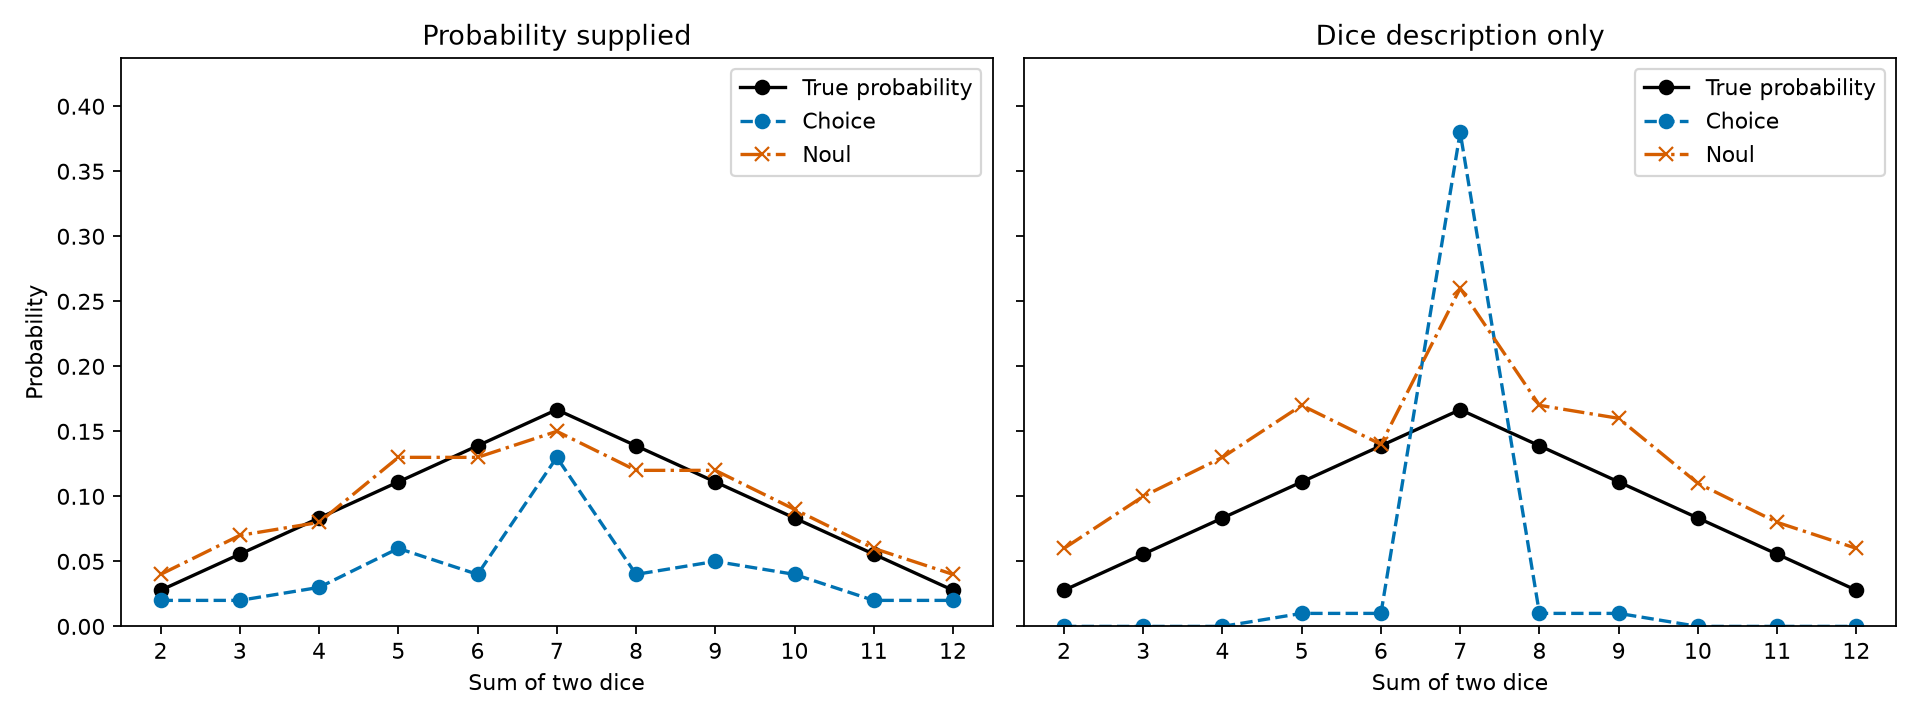

In [29]:
# ruff: noqa: E501
display(Image(filename=str(SOURCE / "dice_predictions.png")))

In [30]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0]
            == "**Figure B1. Dice-sum probability recovery.** The black curve is the exact sum distribution. Colored curves show separate Jev event scores; they need not sum to one."
        )
    )
)

**Figure B1. Dice-sum probability recovery.** The black curve is the exact sum distribution. Colored curves show separate Jev event scores; they need not sum to one.

**Exact request body:**

```json
{
  "state": "Two independent fair six-sided dice, each numbered 1 through 6, will be rolled once. The roll has not happened.",
  "model": "jev-1.13.0",
  "questions": {
    "choice": {
      "type": "choice",
      "instructions": "Which of these outcomes will occur on the next random trial?",
      "criteria": {
        "equals_sum": "The next roll's sum equals 7.",
        "other_sum": "The next roll's sum does not equal 7."
      }
    },
    "event": {
      "type": "noul",
      "instructions": "The next roll's sum equals 7."
    },
    "complement": {
      "type": "noul",
      "instructions": "The next roll's sum does not equal 7."
    }
  }
}
```

**Recorded output fields** (selected from the response; not its full raw body):

```json
{
  "choice_p": 0.38,
  "noul_p": 0.26,
  "complement_p": 0.61
}
```

In [31]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown" and c.source.split("\n", 1)[0] == "### south-german-credit"
        )
    )
)

display(
    Markdown(
        "**Revised matched-record results.** Brier/log loss measure probability quality; ECE diagnoses calibration; AUROC/AP measure discrimination; coverage is reported separately. `legacy correction` retains the original fit. New arms are intercept-only and regularized intercept-plus-slope."
    )
)
display(
    revised_metrics[revised_metrics.condition.eq("south-german-credit")][
        [
            "method",
            "brier",
            "brier_low",
            "brier_high",
            "log_loss",
            "ece10",
            "auroc",
            "average_precision",
            "coverage",
        ]
    ]
)
display(
    paired[
        paired.condition.eq("south-german-credit") & paired.comparison.str.contains("intercept")
    ][["comparison", "uncertainty", "difference", "ci_low", "ci_high", "n_fit_failures"]]
)
display(
    Markdown(
        "**Derived answer-confidence diagnostic.** Fix the chosen binary answer at p ≥ .5, use confidence max(p,1−p), and score against correctness. Its Brier equals event Brier algebraically; it is not separate confidence-elicitation evidence."
    )
)
display(
    revised_metrics[
        revised_metrics.target_kind.eq("answer_confidence")
        & revised_metrics.condition.str.startswith("south-german-credit")
    ][["method", "answer_accuracy", "brier", "log_loss", "ece10", "coverage"]]
)

### south-german-credit

[South German Credit, UCI 522](https://archive.ics.uci.edu/dataset/522/south+german+credit): 1,000 historical credit records, 20 predictors. Positive means a contract was not complied with (`kredit=0`). The corrected codebook was decoded into feature descriptions. Bad credits were oversampled to 30%; this is not a lending-population prevalence.

Training records: 600; calibration: 120; test: 200. Removed duplicate/conflicting rows: 0. Training event rate: 0.300; test event rate: 0.300.

| method | brier | brier_p025 | brier_p975 | ece10 | log_loss | mean_prediction | event_rate |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Choice | 0.2229 | 0.1852 | 0.2633 | 0.1585 | 0.6526 | 0.2479 | 0.3000 |
| Noul | 0.2328 | 0.1898 | 0.2748 | 0.1584 | 0.6866 | 0.2326 | 0.3000 |
| Choice corrected | 0.2060 | 0.1752 | 0.2385 | 0.0871 | 0.5977 | 0.2707 | 0.3000 |
| Noul corrected | 0.2105 | 0.1778 | 0.2445 | 0.0802 | 0.6112 | 0.2726 | 0.3000 |
| Logistic regression | 0.1805 | 0.1485 | 0.2145 | 0.0871 | 0.5562 | 0.3028 | 0.3000 |
| CatBoost | 0.1733 | 0.1384 | 0.2083 | 0.0806 | 0.5284 | 0.2735 | 0.3000 |
| Constant | 0.2100 | 0.1840 | 0.2380 | 0.0000 | 0.6109 | 0.3000 | 0.3000 |

| method | paired_brier_change | paired_change_p025 | paired_change_p975 |
| --- | --- | --- | --- |
| Choice corrected | -0.0169 | -0.0263 | -0.0073 |
| Noul corrected | -0.0223 | -0.0339 | -0.0113 |

**Revised matched-record results.** Brier/log loss measure probability quality; ECE diagnoses calibration; AUROC/AP measure discrimination; coverage is reported separately. `legacy correction` retains the original fit. New arms are intercept-only and regularized intercept-plus-slope.

,method,brier,brier_low,brier_high,log_loss,ece10,auroc,average_precision,coverage
10,Choice,0.222885,0.187463,0.260595,0.652623,1.585000e-01,0.643452,0.402603,1.0
11,Noul,0.232781,0.193534,0.273481,0.686564,1.584000e-01,0.620476,0.393513,1.0
12,Constant,0.210000,0.186000,0.236000,0.610864,5.551115e-17,0.500000,0.300000,1.0
13,Logistic regression,0.180458,0.149910,0.214759,0.556207,8.708218e-02,0.742500,0.573832,1.0
14,CatBoost,0.173272,0.139831,0.209090,0.528367,8.059468e-02,0.787500,0.560403,1.0
15,Choice legacy correction,0.206035,0.176796,0.237411,0.597662,8.705045e-02,0.643452,0.402603,1.0
16,Choice intercept,0.222615,0.187333,0.259408,0.649088,1.641963e-01,0.643452,0.402603,1.0
17,Choice intercept_slope,0.206513,0.177129,0.237982,0.598717,9.068017e-02,0.643452,0.402603,1.0
18,Noul legacy correction,0.210476,0.180572,0.242467,0.611162,8.024858e-02,0.620476,0.393513,1.0
19,Noul intercept,0.231982,0.193898,0.270415,0.675113,1.691162e-01,0.620476,0.393513,1.0


,comparison,uncertainty,difference,ci_low,ci_high,n_fit_failures
20,Choice intercept - Choice,fixed_calibrator,-0.000270,-0.001944,0.001439,0.0
21,Choice intercept - Choice,refit_calibration_independent_test,-0.000270,-0.004875,0.009171,0.0
22,Choice intercept_slope - Choice,fixed_calibrator,-0.016372,-0.025890,-0.007383,0.0
23,Choice intercept_slope - Choice,refit_calibration_independent_test,-0.016372,-0.029147,0.001165,0.0
24,Noul intercept - Noul,fixed_calibrator,-0.000799,-0.005196,0.003477,0.0
25,Noul intercept - Noul,refit_calibration_independent_test,-0.000799,-0.007649,0.008029,0.0
26,Noul intercept_slope - Noul,fixed_calibrator,-0.021728,-0.032861,-0.011467,0.0
27,Noul intercept_slope - Noul,refit_calibration_independent_test,-0.021728,-0.036771,-0.000691,0.0


**Derived answer-confidence diagnostic.** Fix the chosen binary answer at p ≥ .5, use confidence max(p,1−p), and score against correctness. Its Brier equals event Brier algebraically; it is not separate confidence-elicitation evidence.

,method,answer_accuracy,brier,log_loss,ece10,coverage
21,Choice,0.680,0.222885,0.652623,0.1259,1.0
22,Noul,0.685,0.232781,0.686564,0.1643,1.0


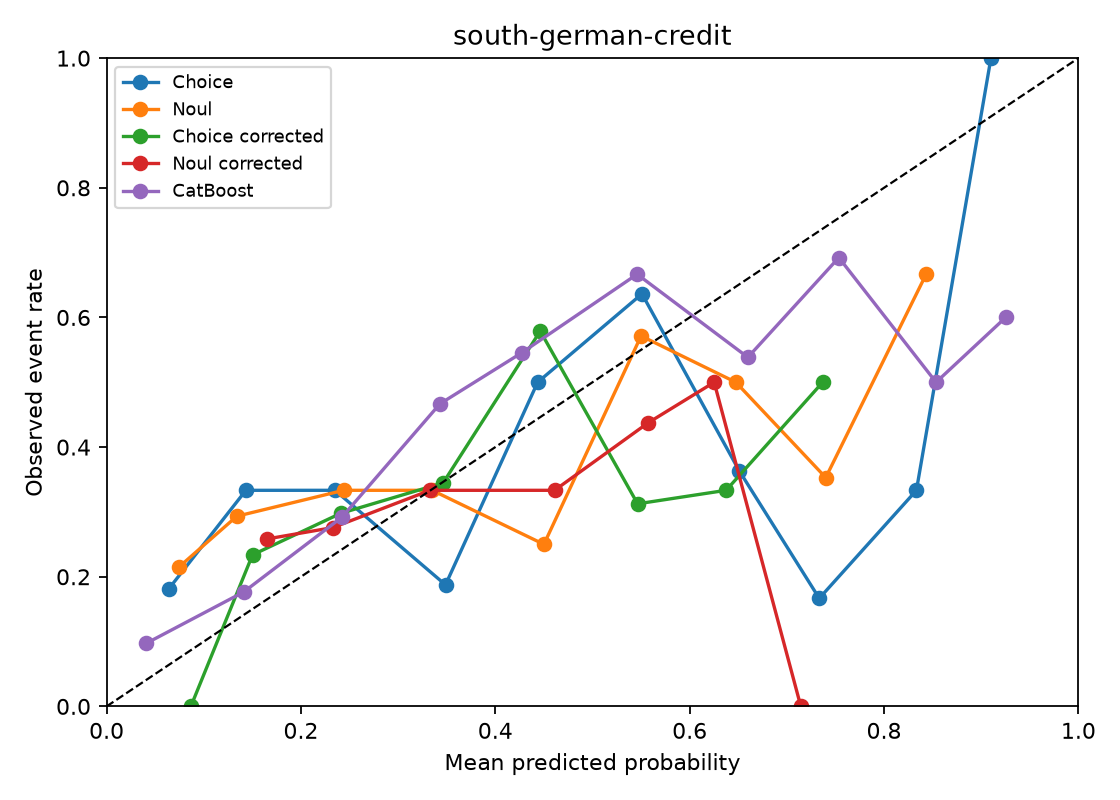

In [32]:
# ruff: noqa: E501
display(Image(filename=str(SOURCE / "south-german-credit-reliability.png")))

In [33]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0]
            == "**Reliability diagram.** Forecast-bin means versus observed event frequencies. The diagonal indicates agreement; sparse bins can fluctuate."
        )
    )
)

**Reliability diagram.** Forecast-bin means versus observed event frequencies. The diagonal indicates agreement; sparse bins can fluctuate.

In [34]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown" and c.source.split("\n", 1)[0] == "### bank-marketing"
        )
    )
)

display(
    Markdown(
        "**Revised matched-record results.** Brier/log loss measure probability quality; ECE diagnoses calibration; AUROC/AP measure discrimination; coverage is reported separately. `legacy correction` retains the original fit. New arms are intercept-only and regularized intercept-plus-slope."
    )
)
display(
    revised_metrics[revised_metrics.condition.eq("bank-marketing")][
        [
            "method",
            "brier",
            "brier_low",
            "brier_high",
            "log_loss",
            "ece10",
            "auroc",
            "average_precision",
            "coverage",
        ]
    ]
)
display(
    paired[paired.condition.eq("bank-marketing") & paired.comparison.str.contains("intercept")][
        ["comparison", "uncertainty", "difference", "ci_low", "ci_high", "n_fit_failures"]
    ]
)
display(
    Markdown(
        "**Derived answer-confidence diagnostic.** Fix the chosen binary answer at p ≥ .5, use confidence max(p,1−p), and score against correctness. Its Brier equals event Brier algebraically; it is not separate confidence-elicitation evidence."
    )
)
display(
    revised_metrics[
        revised_metrics.target_kind.eq("answer_confidence")
        & revised_metrics.condition.str.startswith("bank-marketing")
    ][["method", "answer_accuracy", "brier", "log_loss", "ece10", "coverage"]]
)

### bank-marketing

[Bank Marketing, UCI 222](https://archive.ics.uci.edu/dataset/222/bank+marketing): `bank-additional-full.csv`, 41,188 records. Positive means term-deposit subscription. We removed completed-call duration, leaving 19 predictors. Chronological splitting and filtering change the event rate across partitions.

Training records: 23358; calibration: 120; test: 200. Removed duplicate/conflicting rows: 2258. Training event rate: 0.046; test event rate: 0.340.

| method | brier | brier_p025 | brier_p975 | ece10 | log_loss | mean_prediction | event_rate |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Choice | 0.2223 | 0.1742 | 0.2727 | 0.2029 | 0.7259 | 0.1372 | 0.3400 |
| Noul | 0.1935 | 0.1661 | 0.2215 | 0.0933 | 0.5747 | 0.3010 | 0.3400 |
| Choice corrected | 0.2166 | 0.1742 | 0.2598 | 0.1755 | 0.6463 | 0.1645 | 0.3400 |
| Noul corrected | 0.2716 | 0.2190 | 0.3246 | 0.2217 | 0.8001 | 0.1183 | 0.3400 |
| Logistic regression | 0.3400 | 0.2700 | 0.4100 | 0.3400 | 4.5195 | 0.0000 | 0.3400 |
| CatBoost | 0.2819 | 0.2235 | 0.3354 | 0.2502 | 0.8931 | 0.0940 | 0.3400 |
| Constant | 0.3107 | 0.2472 | 0.3743 | 0.2938 | 1.0770 | 0.0462 | 0.3400 |

| method | paired_brier_change | paired_change_p025 | paired_change_p975 |
| --- | --- | --- | --- |
| Choice corrected | -0.0057 | -0.0139 | 0.0028 |
| Noul corrected | 0.0781 | 0.0451 | 0.1088 |

**Revised matched-record results.** Brier/log loss measure probability quality; ECE diagnoses calibration; AUROC/AP measure discrimination; coverage is reported separately. `legacy correction` retains the original fit. New arms are intercept-only and regularized intercept-plus-slope.

,method,brier,brier_low,brier_high,log_loss,ece10,auroc,average_precision,coverage
23,Choice,0.222262,0.162219,0.288147,0.725854,0.202850,0.743594,0.644357,1.0
24,Noul,0.193522,0.159318,0.231199,0.574682,0.093300,0.701370,0.607130,1.0
25,Constant,0.310747,0.233593,0.406055,1.076968,0.293849,0.500000,0.340000,1.0
26,Logistic regression,0.339988,0.254978,0.444981,4.519544,0.339989,0.497549,0.429018,1.0
27,CatBoost,0.281877,0.212614,0.370037,0.893120,0.250190,0.558601,0.417241,1.0
28,Choice legacy correction,0.216599,0.162024,0.278789,0.646334,0.175536,0.743594,0.644357,1.0
29,Choice intercept,0.197270,0.144505,0.250927,0.612693,0.139687,0.743594,0.644357,1.0
30,Choice intercept_slope,0.209746,0.156448,0.269241,0.632706,0.165735,0.743594,0.644357,1.0
31,Noul legacy correction,0.271636,0.206909,0.350943,0.800057,0.221719,0.701370,0.607130,1.0
32,Noul intercept,0.240523,0.180324,0.310101,0.702660,0.199119,0.701370,0.607130,1.0


,comparison,uncertainty,difference,ci_low,ci_high,n_fit_failures
31,Choice intercept - Choice,fixed_calibrator,-0.024992,-0.038072,-0.014077,0.0
32,Choice intercept - Choice,refit_calibration_independent_test,-0.024992,-0.061073,0.019896,0.0
33,Choice intercept_slope - Choice,fixed_calibrator,-0.012516,-0.019338,-0.006009,0.0
34,Choice intercept_slope - Choice,refit_calibration_independent_test,-0.012516,-0.045557,0.023849,0.0
35,Noul intercept - Noul,fixed_calibrator,0.047001,0.020079,0.080219,0.0
36,Noul intercept - Noul,refit_calibration_independent_test,0.047001,0.004551,0.116467,0.0
37,Noul intercept_slope - Noul,fixed_calibrator,0.038118,0.014002,0.067592,0.0
38,Noul intercept_slope - Noul,refit_calibration_independent_test,0.038118,0.007854,0.085655,0.0


**Derived answer-confidence diagnostic.** Fix the chosen binary answer at p ≥ .5, use confidence max(p,1−p), and score against correctness. Its Brier equals event Brier algebraically; it is not separate confidence-elicitation evidence.

,method,answer_accuracy,brier,log_loss,ece10,coverage
34,Choice,0.715,0.222262,0.725854,0.17215,1.0
35,Noul,0.725,0.193522,0.574682,0.05290,1.0


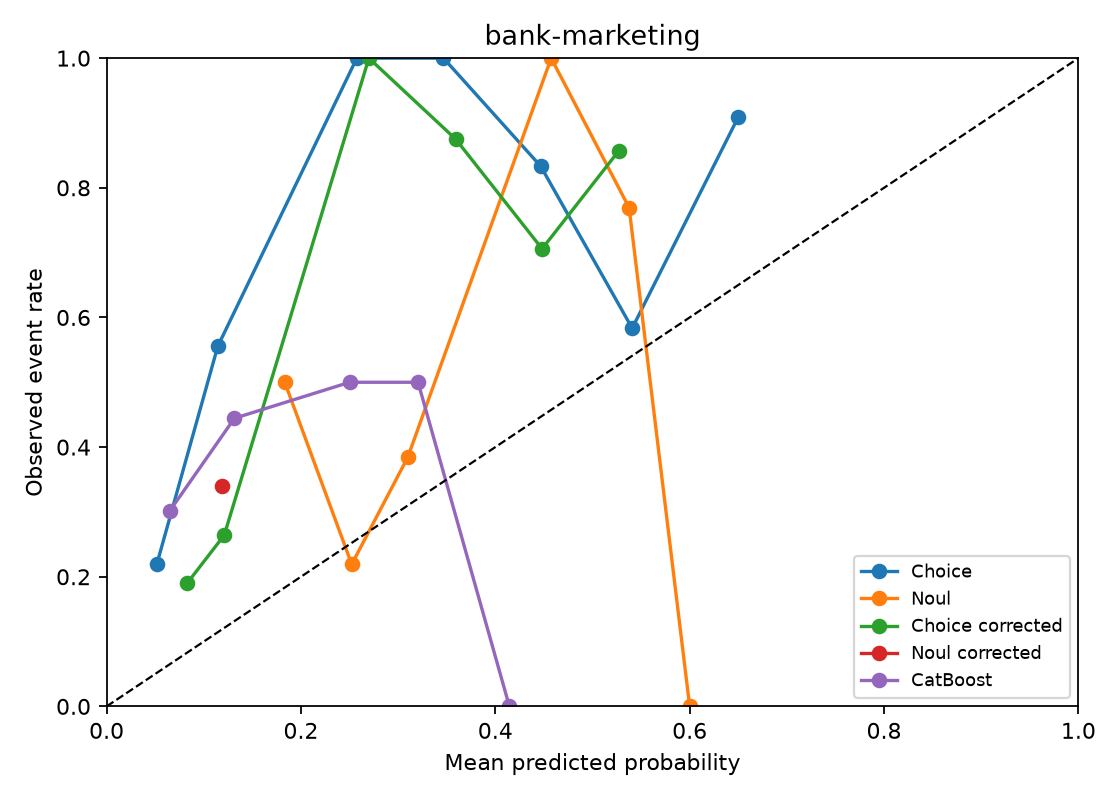

In [35]:
# ruff: noqa: E501
display(Image(filename=str(SOURCE / "bank-marketing-reliability.png")))

In [36]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0]
            == "**Reliability diagram.** Forecast-bin means versus observed event frequencies. The diagonal indicates agreement; sparse bins can fluctuate."
        )
    )
)

**Reliability diagram.** Forecast-bin means versus observed event frequencies. The diagonal indicates agreement; sparse bins can fluctuate.

In [37]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown" and c.source.split("\n", 1)[0] == "### online-shoppers"
        )
    )
)

display(
    Markdown(
        "**Revised matched-record results.** Brier/log loss measure probability quality; ECE diagnoses calibration; AUROC/AP measure discrimination; coverage is reported separately. `legacy correction` retains the original fit. New arms are intercept-only and regularized intercept-plus-slope."
    )
)
display(
    revised_metrics[revised_metrics.condition.eq("online-shoppers")][
        [
            "method",
            "brier",
            "brier_low",
            "brier_high",
            "log_loss",
            "ece10",
            "auroc",
            "average_precision",
            "coverage",
        ]
    ]
)
display(
    paired[paired.condition.eq("online-shoppers") & paired.comparison.str.contains("intercept")][
        ["comparison", "uncertainty", "difference", "ci_low", "ci_high", "n_fit_failures"]
    ]
)
display(
    Markdown(
        "**Derived answer-confidence diagnostic.** Fix the chosen binary answer at p ≥ .5, use confidence max(p,1−p), and score against correctness. Its Brier equals event Brier algebraically; it is not separate confidence-elicitation evidence."
    )
)
display(
    revised_metrics[
        revised_metrics.target_kind.eq("answer_confidence")
        & revised_metrics.condition.str.startswith("online-shoppers")
    ][["method", "answer_accuracy", "brier", "log_loss", "ece10", "coverage"]]
)

### online-shoppers

[Online Shoppers, UCI 468](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset): 12,330 sessions. Positive means a purchase (`Revenue=True`). Removing PageValues leaves 16 predictors. This tests retrospective session classification, not early-session forecasting.

Training records: 7323; calibration: 120; test: 200. Removed duplicate/conflicting rows: 125. Training event rate: 0.156; test event rate: 0.160.

| method | brier | brier_p025 | brier_p975 | ece10 | log_loss | mean_prediction | event_rate |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Choice | 0.3166 | 0.2932 | 0.3405 | 0.3998 | 0.8325 | 0.5598 | 0.1600 |
| Noul | 0.2232 | 0.2146 | 0.2322 | 0.2930 | 0.6377 | 0.4530 | 0.1600 |
| Choice corrected | 0.1344 | 0.1017 | 0.1671 | 0.0115 | 0.4391 | 0.1715 | 0.1600 |
| Noul corrected | 0.1363 | 0.1033 | 0.1695 | 0.0159 | 0.4447 | 0.1678 | 0.1600 |
| Logistic regression | 0.1240 | 0.0925 | 0.1559 | 0.0757 | 0.3961 | 0.1591 | 0.1600 |
| CatBoost | 0.1255 | 0.0934 | 0.1582 | 0.0628 | 0.3943 | 0.1446 | 0.1600 |
| Constant | 0.1344 | 0.1000 | 0.1688 | 0.0036 | 0.4397 | 0.1564 | 0.1600 |

| method | paired_brier_change | paired_change_p025 | paired_change_p975 |
| --- | --- | --- | --- |
| Choice corrected | -0.1822 | -0.2282 | -0.1367 |
| Noul corrected | -0.0869 | -0.1171 | -0.0566 |

**Revised matched-record results.** Brier/log loss measure probability quality; ECE diagnoses calibration; AUROC/AP measure discrimination; coverage is reported separately. `legacy correction` retains the original fit. New arms are intercept-only and regularized intercept-plus-slope.

,method,brier,brier_low,brier_high,log_loss,ece10,auroc,average_precision,coverage
36,Choice,0.316630,0.294681,0.339513,0.832530,0.399850,0.511533,0.169902,1.0
37,Noul,0.223181,0.214122,0.232028,0.637675,0.293000,0.505673,0.163185,1.0
38,Constant,0.134413,0.100049,0.172214,0.439720,0.003643,0.500000,0.160000,1.0
39,Logistic regression,0.123997,0.091915,0.155907,0.396067,0.075689,0.695871,0.367372,1.0
40,CatBoost,0.125523,0.092942,0.157847,0.394345,0.062759,0.728051,0.333491,1.0
41,Choice legacy correction,0.134380,0.100579,0.169507,0.439069,0.011500,0.511533,0.169902,1.0
42,Choice intercept,0.139143,0.102834,0.175901,0.458641,0.051543,0.511533,0.169902,1.0
43,Choice intercept_slope,0.134860,0.102090,0.168467,0.440580,0.023586,0.511533,0.169902,1.0
44,Noul legacy correction,0.136308,0.101306,0.171667,0.444685,0.015934,0.505673,0.163185,1.0
45,Noul intercept,0.135150,0.100891,0.169893,0.441143,0.011367,0.505673,0.163185,1.0


,comparison,uncertainty,difference,ci_low,ci_high,n_fit_failures
48,Choice intercept - Choice,fixed_calibrator,-0.177487,-0.222655,-0.133733,0.0
49,Choice intercept - Choice,refit_calibration_independent_test,-0.177487,-0.220866,-0.131804,0.0
50,Choice intercept_slope - Choice,fixed_calibrator,-0.181769,-0.226621,-0.140022,0.0
51,Choice intercept_slope - Choice,refit_calibration_independent_test,-0.181769,-0.224784,-0.134773,0.0
52,Noul intercept - Noul,fixed_calibrator,-0.088031,-0.117838,-0.057051,0.0
53,Noul intercept - Noul,refit_calibration_independent_test,-0.088031,-0.117504,-0.056712,0.0
54,Noul intercept_slope - Noul,fixed_calibrator,-0.086933,-0.116012,-0.057031,0.0
55,Noul intercept_slope - Noul,refit_calibration_independent_test,-0.086933,-0.115383,-0.056954,0.0


**Derived answer-confidence diagnostic.** Fix the chosen binary answer at p ≥ .5, use confidence max(p,1−p), and score against correctness. Its Brier equals event Brier algebraically; it is not separate confidence-elicitation evidence.

,method,answer_accuracy,brier,log_loss,ece10,coverage
47,Choice,0.34,0.316630,0.832530,0.30595,1.0
48,Noul,0.69,0.223181,0.637675,0.13110,1.0


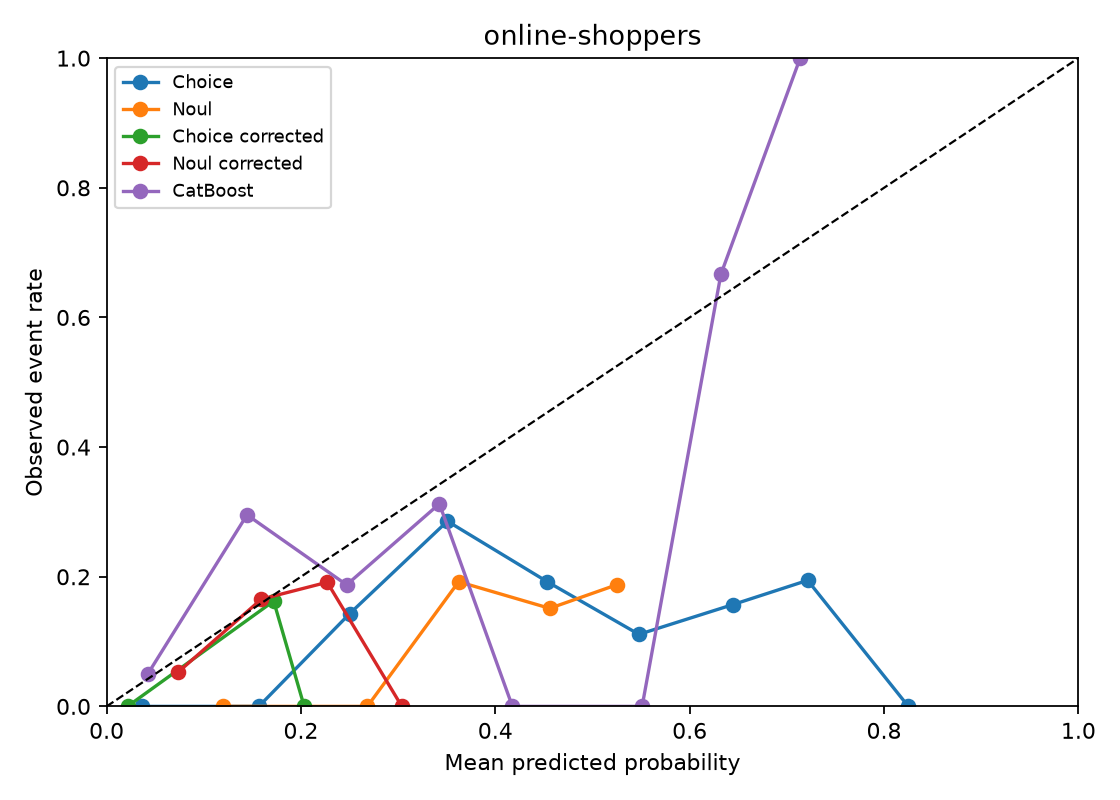

In [38]:
# ruff: noqa: E501
display(Image(filename=str(SOURCE / "online-shoppers-reliability.png")))

In [39]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0]
            == "**Reliability diagram.** Forecast-bin means versus observed event frequencies. The diagonal indicates agreement; sparse bins can fluctuate."
        )
    )
)

**Reliability diagram.** Forecast-bin means versus observed event frequencies. The diagonal indicates agreement; sparse bins can fluctuate.

In [40]:
# ruff: noqa: E501
display(
    Markdown(
        next(
            c.source
            for c in report_cells.cells
            if c.cell_type == "markdown"
            and c.source.split("\n", 1)[0] == "### Artifacts and provenance"
        )
    )
)

display(
    Markdown(
        f"Revised statistics and their full audit: `{REVISION.relative_to(ROOT)}`. This execution's derived figures and EDA: `{RUN.relative_to(ROOT)}`. Historical artifacts remain unchanged; no paid inference ran."
    )
)
display(
    pd.Series(
        json.loads((REVISION / "evidence_counts.json").read_text()), name="Count / interpretation"
    )
)
revision_manifest = json.loads((REVISION / "analysis_manifest.json").read_text())
assert all(
    hashlib.sha256((ROOT / path).read_bytes()).hexdigest() == sha
    for path, sha in revision_manifest["historical_sha256"].items()
)
(RUN / "revision_manifest.json").write_text(
    json.dumps(
        {
            "pilot_source": str(SOURCE.relative_to(ROOT)),
            "statistical_revision": str(REVISION.relative_to(ROOT)),
            "notebook_layout": "original 50 cells and original section order",
            "new_api_calls": 0,
            "historical_files_verified": len(revision_manifest["historical_sha256"]),
        },
        indent=2,
    )
    + "\n"
)

### Artifacts and provenance

`requests.json` stores complete input bodies and local label/split metadata; only its `payload` object was sent. `responses/` stores selected probability fields, not full raw API responses. `all_predictions.csv`, `baseline_predictions.csv`, `uci_metrics.csv`, `calibration_fits.csv`, and per-dataset split manifests retain the evidence. Seeds, dataset hashes, request hashes, and baseline settings are recorded. Source datasets and the chart inspiration are attributed in the project reference index.

Experiment files are saved in `/Users/han/projects/SMILE-factory/research/jev/runs/04-jev-calibration-20260920T074937231226Z`. The coin and dice tables above contain every synthetic case for those experiments. `all_predictions.csv` contains all 1,045 records; `synthetic_task_summary.csv` contains the separate task summaries.

Revised statistics and their full audit: `runs/revised-exploratory-v1`. This execution's derived figures and EDA: `runs/04-jev-calibration-revised-20260922T050337437781Z`. Historical artifacts remain unchanged; no paid inference ran.

independent_customer_count                        unknown; customer IDs unavailable
distinct_source_records_with_predictions                                        960
real_calibration_records                                                        360
real_exploratory_test_records                                                   600
synthetic_event_definitions                                                      50
synthetic_generating_configurations                                              24
synthetic_prompt_variants                                                        85
repeated_api_calls_per_identical_prompt                                           0
question_outputs_per_successful_api_call                                          3
historical_mc_repetitions                                                       500
historical_mc_trials_per_repetition                                            2000
additional_model_evaluations_from_mc                                        

256